# TP3 (cas Big) : vélos en libre-service à Chicago avec Hadoop + Spark

**Quentin Chamberlan**, FISA 5A · identifiant 12 · cours *Fondements et Application de Big Data* · rendu mis à jour le 13/11/2026

## Ma contribution

**Le notebook est-il correct ?** Oui : il s'exécute de bout en bout sans erreur (41 cellules de code, 19 tests
sur 19 OK, bilan en partie 8). Il demande Docker (HDFS) et environ 1 Go de téléchargement.

**Origine :** cas personnel. Les données (trajets Divvy 2024, météo Open-Meteo) et la question sont de mon
choix ; le notebook est écrit entièrement, il n'adapte pas un notebook existant. Il utilise déjà PySpark
(Spark SQL + MLlib) et HDFS.

**Problèmes rencontrés et solutions :**
- Spark tourne sous Windows et HDFS dans Docker : il a fallu ouvrir les ports du DataNode et régler
  `dfs.client.use.datanode.hostname`, sinon le NameNode renvoie une adresse interne à Docker ;
- un nom de station contient des guillemets doublés (`Senka "Edward Duke" Park`) : lecture avec `escape='"'` ;
- la météo est en UTC : conversion à l'heure de Chicago, heure d'été comprise ;
- sous Windows, Spark a besoin de `winutils.exe` / `hadoop.dll` pour écrire le modèle, et le chemin du modèle
  MLlib dépasse 260 caractères (`git config core.longpaths true`) ;
- le gradient boosting n'est pas monotone en la pluie (une forte averse d'été peut faire monter la prévision) :
  limite expliquée en partie 6.

**Modifications apportées pour ce rendu :** cellules d'étapes `## [...]` et cette cellule ; rangement dans
`TP3_ID12/Big/`.

**Autres informations :** résultat principal : GBT, RMSE 1,739 départ / heure, R² 0,604 (contre 0,392 pour la
moyenne historique). L'appli `app_velos.py` (Streamlit) sert le modèle MLlib sauvegardé.

## Présentation

**Cours :** Fondements et Application de Big Data, TP 3 (novembre 2026)
**Question :** combien de vélos vont partir de chaque station, heure par heure ?

## Consigne

| # | À faire |
|---|---------|
| 1 | Un exemple « petit » avec tout le workflow (c'est le premier notebook, `tokyo_immo.ipynb`) |
| 2 | **Big Data + Hadoop / Spark + le même workflow** : c'est ce notebook |
| 3 | Publier le résultat sur GitHub |

**Le cas.** [Divvy](https://divvybikes.com/system-data) est le service de vélos en libre-service de Chicago
(environ 1 800 stations). La ville publie chaque mois la liste de **tous les trajets** : station et heure de
départ, station et heure d'arrivée, type de vélo, abonné ou non. En 2024, cela fait **près de 6 millions de
trajets** et 1,1 Go de fichiers CSV. Le même jeu de données est repris sur Kaggle (par exemple
*Divvy Tripdata Nov 2023 - Oct 2024*) ; on télécharge ici les fichiers officiels de l'année civile 2024.

**Pourquoi prédire les départs ?** Chaque jour, des camionnettes déplacent des vélos des stations pleines vers
les stations vides. Savoir combien de vélos partiront de chaque station dans les prochaines heures permet de
préparer ces tournées. On ajoute la **météo heure par heure** (personne ne pédale sous l'orage à −10 °C).

## Pourquoi c'est du « Big Data » ici

| | Sujet 1 : Tokyo | Sujet 2 : Chicago |
|---|---|---|
| Données brutes | 1 fichier CSV, 104 Mo | 12 fichiers CSV, 1,1 Go |
| Lignes | 406 000 ventes | 5,9 millions de trajets |
| Table d'apprentissage | 160 000 lignes | 2,6 millions de lignes (300 stations × 8 783 heures) |
| Stockage | disque local | **HDFS** (Hadoop), découpé en blocs |
| Calcul | pandas + scikit-learn, un seul cœur la plupart du temps | **Spark** + **MLlib**, calcul réparti sur tous les cœurs |

Sur un portable, 1 Go passe encore en mémoire. Mais la même chaîne, écrite en Spark sur HDFS, fonctionnerait
**sans changer une ligne** sur un vrai cluster avec 10 ans de trajets de toutes les villes : il suffirait de
changer l'adresse du cluster. C'est tout l'intérêt de Hadoop et Spark.

## Plan

0. Architecture : HDFS dans Docker, Spark en local
1. Data : télécharger, envoyer dans HDFS, lire avec Spark
2. EDA : explorer 6 millions de trajets avec Spark
3. Prétraitement : nettoyer et sauvegarder en Parquet dans HDFS
4. Transformation : passer des trajets aux « départs par station et par heure » + météo
5. ML : trois modèles Spark MLlib
6. Évaluation
7. Déploiement : modèle sauvegardé + appli Streamlit
8. Bilan des tests et conclusion

## [Environnement]

In [1]:
import os, sys, re, io, json, time, math, shutil, platform, subprocess, zipfile, urllib.request
from pathlib import Path

os.environ["PYSPARK_PYTHON"] = sys.executable          # Windows : Spark doit utiliser ce Python
os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable
# Windows : Spark a besoin de winutils.exe et hadoop.dll (dossier HADOOP_HOMEin) pour lire et écrire des
# dossiers locaux, par exemple pour recharger le modèle sauvegardé. Voir le README.
if platform.system() == "Windows" and "HADOOP_HOME" not in os.environ and (Path.home() / "hadoop-3.3.5").exists():
    os.environ["HADOOP_HOME"] = str(Path.home() / "hadoop-3.3.5")
if os.environ.get("HADOOP_HOME"):
    os.environ["PATH"] = os.path.join(os.environ["HADOOP_HOME"], "bin") + os.pathsep + os.environ["PATH"]

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import pyspark
from pyspark.sql import SparkSession, functions as F, types as T

from outils import (style, verifier, bilan_tests, schema, workflow,
                    BLEU, ORANGE, VERT_EAU, JAUNE, VIOLET, ROUGE, GRIS, ENCRE_2, SEQUENTIEL)

style()
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

java = subprocess.run("java -version", shell=True, capture_output=True, text=True)
docker = subprocess.run(["docker", "--version"], capture_output=True, text=True)
print("Python  :", sys.version.split()[0], "  ", platform.system(), platform.release(), "-", os.cpu_count(), "cœurs logiques")
print("PySpark :", pyspark.__version__)
print("Java    :", (java.stderr or java.stdout).splitlines()[0])
print("Docker  :", docker.stdout.strip())
print("pandas  :", pd.__version__)

Python  : 3.11.9    Windows 10 - 12 cœurs logiques
PySpark : 3.5.9
Java    : java version "1.8.0_471"
Docker  : Docker version 28.4.0, build d8eb465
pandas  : 2.3.0


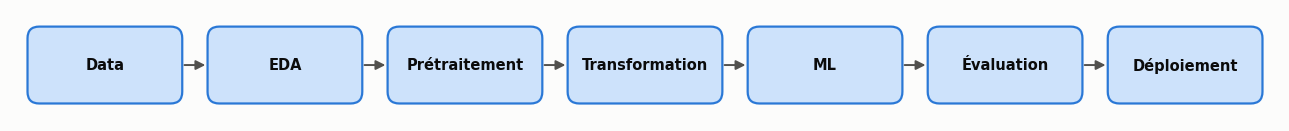

In [2]:
workflow()

## [Architecture]

## 0. Architecture

Deux briques Big Data :

- **HDFS** (*Hadoop Distributed File System*) **stocke** les fichiers. Il les coupe en **blocs de 128 Mo**
  répartis sur des machines appelées **DataNodes** ; le **NameNode** retient seulement où se trouve chaque bloc.
  Ici, HDFS tourne dans deux conteneurs Docker (image officielle `apache/hadoop:3.4.1`, fichier
  `hadoop/docker-compose.yml`) : un NameNode et un DataNode.
- **Spark** **calcule**. Il découpe le travail en **tâches**, une par morceau de données (une *partition*), et
  les exécute en parallèle. Ici Spark tourne en mode `local[*]` : un seul ordinateur, mais toutes ses
  tâches en parallèle sur les 12 cœurs. Sur un cluster, ce serait la même chose avec des dizaines de machines.
  **MLlib** est la bibliothèque d'apprentissage automatique de Spark.

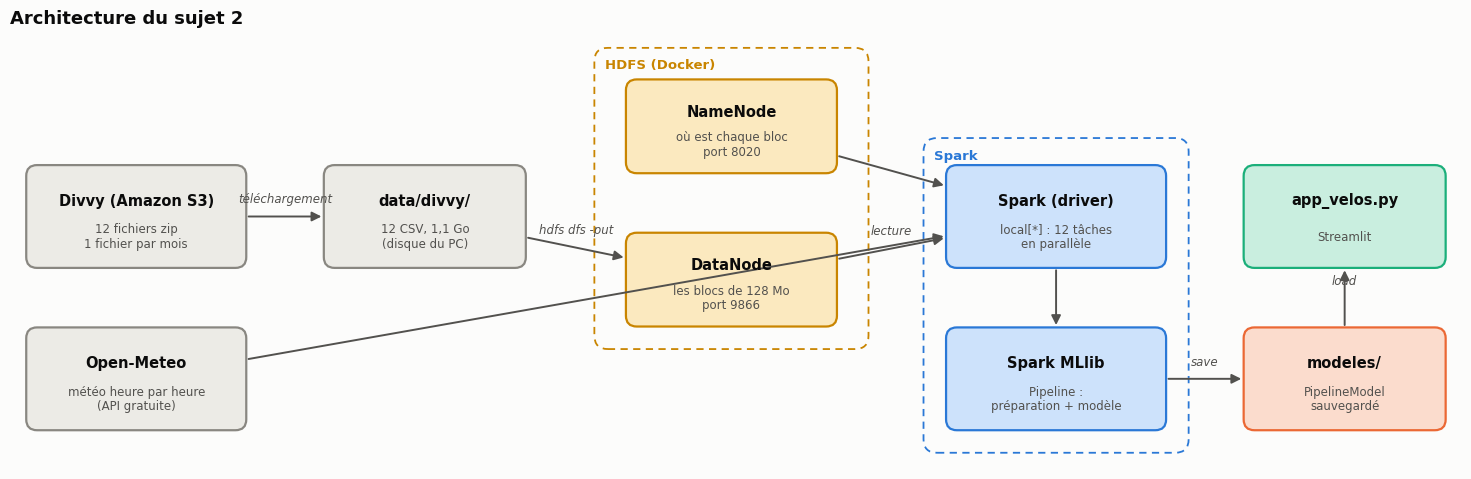

In [3]:
schema([
    dict(id="s3", x=0, y=2.2, texte="Divvy (Amazon S3)", sous="12 fichiers zip\n1 fichier par mois", couleur="gris", l=2.4, h=1.1),
    dict(id="meteo", x=0, y=0.4, texte="Open-Meteo", sous="météo heure par heure\n(API gratuite)", couleur="gris", l=2.4, h=1.1),
    dict(id="local", x=3.2, y=2.2, texte="data/divvy/", sous="12 CSV, 1,1 Go\n(disque du PC)", couleur="gris", l=2.2, h=1.1),
    dict(id="nn", x=6.6, y=3.2, texte="NameNode", sous="où est chaque bloc\nport 8020", couleur="jaune", l=2.3, h=1.0),
    dict(id="dn", x=6.6, y=1.5, texte="DataNode", sous="les blocs de 128 Mo\nport 9866", couleur="jaune", l=2.3, h=1.0),
    dict(id="spark", x=10.2, y=2.2, texte="Spark (driver)", sous="local[*] : 12 tâches\nen parallèle", couleur="bleu", l=2.4, h=1.1),
    dict(id="mllib", x=10.2, y=0.4, texte="Spark MLlib", sous="Pipeline :\npréparation + modèle", couleur="bleu", l=2.4, h=1.1),
    dict(id="mod", x=13.4, y=0.4, texte="modeles/", sous="PipelineModel\nsauvegardé", couleur="orange", l=2.2, h=1.1),
    dict(id="app", x=13.4, y=2.2, texte="app_velos.py", sous="Streamlit", couleur="vert", l=2.2, h=1.1),
], [("s3", "local", "téléchargement"), ("local", "dn", "hdfs dfs -put"), ("nn", "spark", ""), ("dn", "spark", "lecture"),
    ("meteo", "spark"), ("spark", "mllib"), ("mllib", "mod", "save"), ("mod", "app", "load")],
   taille=(15, 4.8), titre="Architecture du sujet 2",
   cadres=[dict(x0=5.1, y0=0.75, x1=8.1, y1=4.05, texte="HDFS (Docker)", couleur="jaune"),
           dict(x0=8.75, y0=-0.4, x1=11.65, y1=3.05, texte="Spark", couleur="bleu")])

### Démarrer HDFS

```bash
cd hadoop
docker compose up -d
```

Deux réglages permettent à Spark, qui tourne sous Windows **en dehors** de Docker, de lire HDFS : les ports du
NameNode (8020) et du DataNode (9866) sont ouverts, et le DataNode se présente sous le nom `localhost`
(sinon il donnerait son nom interne à Docker, inconnu de Windows). La petite fonction `hdfs()` lance une commande
HDFS dans le conteneur du NameNode.

In [4]:
NAMENODE = "tp-bigdata-ml-namenode-1"
HDFS = "hdfs://localhost:8020"

def hdfs(*args):
    # Lance `hdfs <args>` dans le conteneur du NameNode et renvoie la sortie texte.
    r = subprocess.run(["docker", "exec", NAMENODE, "bash", "-c", "hdfs " + " ".join(args)],
                       capture_output=True, text=True, encoding="utf-8", errors="replace")
    if r.returncode != 0:
        raise RuntimeError(r.stderr[-2000:])
    return r.stdout

etat = subprocess.run(["docker", "ps", "--format", "{{.Names}} : {{.Status}}"], capture_output=True, text=True).stdout
print("\n".join(l for l in etat.splitlines() if "tp-bigdata-ml" in l))
rapport = hdfs("dfsadmin", "-report")
noeuds = int(re.search(r"Live datanodes \((\d+)\)", rapport).group(1))
print("DataNodes en vie :", noeuds)
verifier("HDFS répond et a un DataNode en vie", noeuds >= 1, noeuds)

tp-bigdata-ml-datanode-1 : Up 2 hours
tp-bigdata-ml-namenode-1 : Up 2 hours


DataNodes en vie : 1
OK     HDFS répond et a un DataNode en vie  (1)


## [Data]

## 1. Data : télécharger, envoyer dans HDFS, lire avec Spark

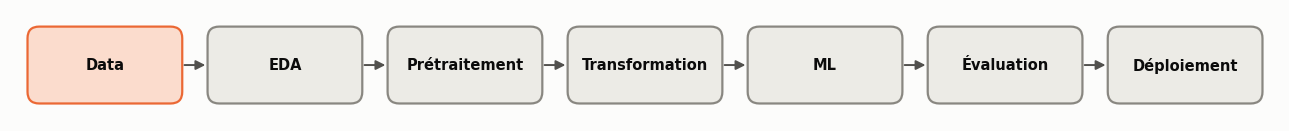

In [5]:
workflow(actif=1)

### 1.1 Téléchargement

Les fichiers mensuels sont publiés sur un espace Amazon S3 public. On ne les télécharge que s'ils manquent
(le dossier `data/` n'est pas versionné).

In [6]:
DOSSIER = Path("data/divvy"); DOSSIER.mkdir(parents=True, exist_ok=True)
MOIS = [f"2024{m:02d}" for m in range(1, 13)]
for m in MOIS:
    csv = DOSSIER / f"{m}-divvy-tripdata.csv"
    if not csv.exists():
        url = f"https://divvy-tripdata.s3.amazonaws.com/{m}-divvy-tripdata.zip"
        with zipfile.ZipFile(io.BytesIO(urllib.request.urlopen(url).read())) as z:
            z.extract(f"{m}-divvy-tripdata.csv", DOSSIER)

tailles = pd.Series({m: (DOSSIER / f"{m}-divvy-tripdata.csv").stat().st_size / 1e6 for m in MOIS})
print(f"12 fichiers, {tailles.sum():,.0f} Mo au total")
verifier("les 12 fichiers mensuels de 2024 sont là", len(tailles) == 12 and tailles.min() > 10)

12 fichiers, 1,189 Mo au total
OK     les 12 fichiers mensuels de 2024 sont là


### 1.2 Envoi dans HDFS

Le dossier `data/` du projet est monté dans le conteneur du NameNode (sous `/data`) : la commande
`hdfs dfs -put` copie les fichiers dans HDFS, qui les découpe en blocs.

In [7]:
t0 = time.perf_counter()
hdfs("dfs", "-mkdir", "-p", "/divvy/brut")
hdfs("dfs", "-put", "-f", "/data/divvy/*.csv", "/divvy/brut/")
print(f"Envoi dans HDFS : {time.perf_counter() - t0:.0f} s\n")
print(hdfs("dfs", "-du", "-s", "-h", "/divvy/brut"))
fsck = hdfs("fsck", "/divvy/brut", "-files", "-blocks")
print("\n".join(l.strip() for l in fsck.splitlines()
                if re.search(r"Total size|Total files|Total blocks|Default replication|Status", l)))

Envoi dans HDFS : 102 s



1.1 G  1.1 G  /divvy/brut



Status: HEALTHY
Total size:	1189139393 B
Total files:	12
Total blocks (validated):	16 (avg. block size 74321212 B)
Default replication factor:	1
Total size:	0 B
Total files:	0


OK     12 fichiers dans HDFS  (12)
OK     nombre de blocs = somme des arrondis supérieurs (taille / 128 Mio)  (16)


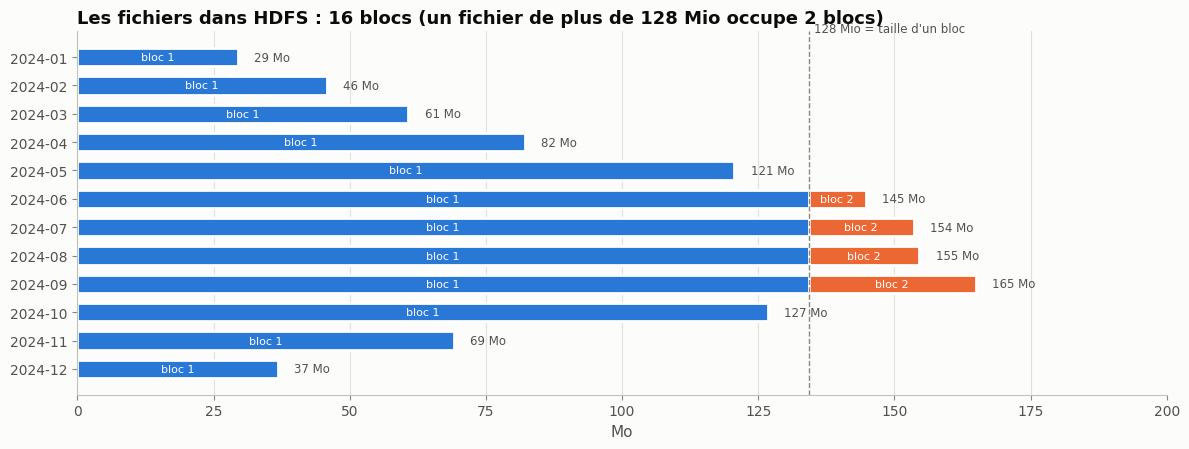

In [8]:
# Combien de blocs pour chaque fichier ? (lu dans le rapport fsck)
blocs = {}
for nom, taille, n in re.findall(r"/divvy/brut/(\d{6})-divvy-tripdata\.csv (\d+) bytes.*?(\d+) block\(s\)", fsck):
    blocs[nom] = (int(taille), int(n))
total_blocs = int(re.search(r"Total blocks \(validated\):\s+(\d+)", fsck).group(1))
BLOC = 128 * 1024 * 1024
verifier("12 fichiers dans HDFS", len(blocs) == 12, len(blocs))
verifier("nombre de blocs = somme des arrondis supérieurs (taille / 128 Mio)",
         total_blocs == sum(math.ceil(t / BLOC) for t, _ in blocs.values()), total_blocs)

fig, ax = plt.subplots(figsize=(12, 4.6))
for i, (m, (taille, n)) in enumerate(sorted(blocs.items())):
    reste = taille
    for b in range(n):
        larg = min(reste, BLOC) / 1e6
        ax.barh(i, larg, left=b * BLOC / 1e6, color=[BLEU, ORANGE][b % 2], height=0.65, edgecolor="white", lw=2)
        ax.text(b * BLOC / 1e6 + larg / 2, i, f"bloc {b + 1}", ha="center", va="center", fontsize=8, color="white")
        reste -= BLOC
    ax.text(taille / 1e6 + 3, i, f"{taille / 1e6:.0f} Mo", va="center", fontsize=8.5, color=ENCRE_2)
ax.set_yticks(range(len(blocs)), [f"{m[:4]}-{m[4:]}" for m in sorted(blocs)]); ax.invert_yaxis()
ax.axvline(BLOC / 1e6, color=GRIS, ls="--", lw=1)
ax.text(BLOC / 1e6 + 1, -0.9, "128 Mio = taille d'un bloc", fontsize=8.5, color=ENCRE_2)
ax.set_xlabel("Mo"); ax.set_xlim(0, 200); ax.grid(axis="y", visible=False)
ax.set_title(f"Les fichiers dans HDFS : {total_blocs} blocs (un fichier de plus de 128 Mio occupe 2 blocs)")
plt.tight_layout(); plt.show()

Les fichiers des mois d'été dépassent 128 Mio : HDFS les coupe en deux blocs. Sur un vrai cluster, chaque bloc
serait copié sur 3 DataNodes différents (réplication 3) et Spark lancerait une tâche **sur la machine qui
possède le bloc** : on déplace le calcul vers les données, pas l'inverse. Ici, un seul DataNode, donc
réplication 1.

### 1.3 Lecture avec Spark

La session Spark se connecte à HDFS. On donne le **schéma** des colonnes à l'avance : Spark n'a pas besoin de
relire tout le fichier pour deviner les types.

In [9]:
t0 = time.perf_counter()
spark = (SparkSession.builder.master("local[*]").appName("Velos Chicago")
         .config("spark.driver.memory", "6g")
         .config("spark.sql.shuffle.partitions", "48")
         .config("spark.sql.session.timeZone", "UTC")                     # heures lues telles qu'écrites
         .config("spark.ui.showConsoleProgress", "false")
         .config("spark.python.authenticate.socketTimeout", "3600s")      # Windows : délai Java <-> Python
         .config("spark.hadoop.dfs.client.use.datanode.hostname", "true")  # DataNode joint par son nom
         .config("spark.hadoop.dfs.replication", "1")                      # un seul DataNode : une seule copie
         .getOrCreate())
spark.sparkContext.setLogLevel("ERROR")
print(f"Session Spark {spark.version} prête en {time.perf_counter() - t0:.1f} s,",
      spark.sparkContext.defaultParallelism, "tâches en parallèle")

schema_trajets = T.StructType([T.StructField(c, T.StringType()) for c in
    ["ride_id", "rideable_type", "started_at", "ended_at", "start_station_name", "start_station_id",
     "end_station_name", "end_station_id"]] +
    [T.StructField(c, T.DoubleType()) for c in ["start_lat", "start_lng", "end_lat", "end_lng"]] +
    [T.StructField("member_casual", T.StringType())])

# escape='"' : dans ces CSV, un guillemet dans un nom est doublé ("" ) ; par défaut Spark attend \" et lirait
# mal le nom de la station Public Rack - Senka "Edward Duke" Park.
brut = spark.read.csv(f"{HDFS}/divvy/brut/", header=True, schema=schema_trajets, escape='"')
print("Partitions lues :", brut.rdd.getNumPartitions())
t0 = time.perf_counter()
n_brut = brut.count()
print(f"{n_brut:,} trajets comptés en {time.perf_counter() - t0:.1f} s")
verifier("près de 6 millions de trajets en 2024", 5_500_000 < n_brut < 6_500_000, f"{n_brut:,}")
brut.limit(3).toPandas().T

Session Spark 3.5.9 prête en 7.4 s, 12 tâches en parallèle


Partitions lues : 14


5,860,568 trajets comptés en 10.9 s
OK     près de 6 millions de trajets en 2024  (5,860,568)


,0,1,2
ride_id,7D9F0CE9EC2A1297,02EC47687411416F,101370FB2D3402BE
rideable_type,classic_bike,classic_bike,classic_bike
started_at,2024-05-25 15:52:42,2024-05-14 15:11:51,2024-05-30 17:46:04
ended_at,2024-05-25 16:11:50,2024-05-14 15:22:00,2024-05-30 18:09:16
start_station_name,Streeter Dr & Grand Ave,Sheridan Rd & Greenleaf Ave,Streeter Dr & Grand Ave
start_station_id,13022,KA1504000159,13022
end_station_name,Clark St & Elm St,Sheridan Rd & Loyola Ave,Wabash Ave & 9th St
end_station_id,TA1307000039,RP-009,TA1309000010
start_lat,41.892278,42.010587,41.892278
start_lng,-87.612043,-87.662412,-87.612043


| Colonne | Signification |
|---|---|
| `ride_id` | identifiant du trajet |
| `rideable_type` | vélo classique, vélo électrique ou trottinette électrique |
| `started_at`, `ended_at` | date et heure de départ et d'arrivée (heure de Chicago) |
| `start_station_name`, `end_station_name` | stations de départ et d'arrivée (vides si le vélo électrique a été pris ou laissé hors station) |
| `start_lat`, `start_lng`, ... | coordonnées GPS |
| `member_casual` | `member` = abonné annuel, `casual` = usager occasionnel (ticket ou pass journée) |

**Évaluation paresseuse.** `spark.read.csv` n'a rien lu : Spark a seulement noté le plan. La lecture n'a eu lieu
qu'au `count()`, une **action**. Les transformations (`filter`, `groupBy`...) s'empilent sans rien calculer ;
Spark optimise tout le plan au moment de l'action.

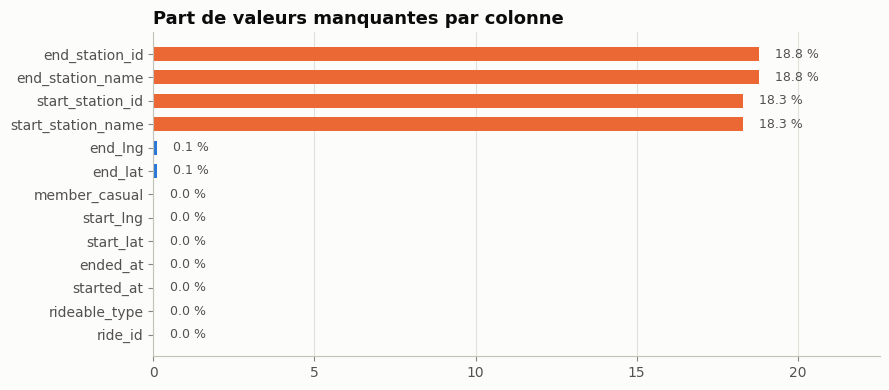

In [10]:
manquants = brut.select([F.round(F.avg(F.col(c).isNull().cast("int")) * 100, 1).alias(c) for c in brut.columns]).toPandas().T[0]
manquants = manquants.sort_values()
fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(manquants.index, manquants.values, color=[ORANGE if v > 5 else BLEU for v in manquants.values], height=0.6)
for i, v in enumerate(manquants.values):
    ax.text(v + 0.5, i, f"{v:.1f} %", va="center", fontsize=9, color=ENCRE_2)
ax.set_title("Part de valeurs manquantes par colonne"); ax.set_xlim(0, manquants.max() * 1.2)
ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

Environ un trajet sur cinq n'a pas de station de départ : ce sont des vélos électriques pris là où le
précédent usager les avait laissés, attachés à un poteau. Pour prédire les départs **par station**, on ne pourra
garder que les trajets partis d'une station.

## [EDA]

## 2. EDA : explorer 6 millions de trajets

Toutes les agrégations sont faites **par Spark** ; seuls les résultats (quelques centaines de lignes) sont
ramenés dans pandas avec `toPandas()` pour dessiner. On ne ramène jamais les 6 millions de lignes.

On prépare d'abord quelques colonnes de temps et la durée du trajet.

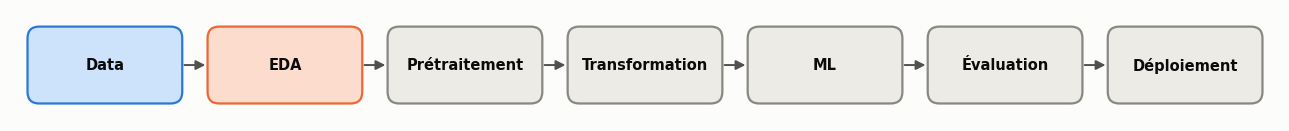

In [11]:
workflow(actif=2)

In [12]:
trajets = (brut
    .withColumn("depart", F.to_timestamp("started_at"))
    .withColumn("arrivee", F.to_timestamp("ended_at"))
    .withColumn("duree_min", (F.col("arrivee").cast("long") - F.col("depart").cast("long")) / 60)
    .withColumn("mois", F.month("depart"))
    .withColumn("heure", F.hour("depart"))
    .withColumn("jour_semaine", F.dayofweek("depart"))           # 1 = dimanche ... 7 = samedi
    .withColumn("weekend", F.col("jour_semaine").isin(1, 7).cast("int"))
    .withColumn("date", F.to_date("depart")))
trajets.cache()
t0 = time.perf_counter(); trajets.count()
print(f"Colonnes calculées et données mises en cache en mémoire en {time.perf_counter() - t0:.0f} s")

Colonnes calculées et données mises en cache en mémoire en 32 s


### 2.1 Saisons et types d'usagers

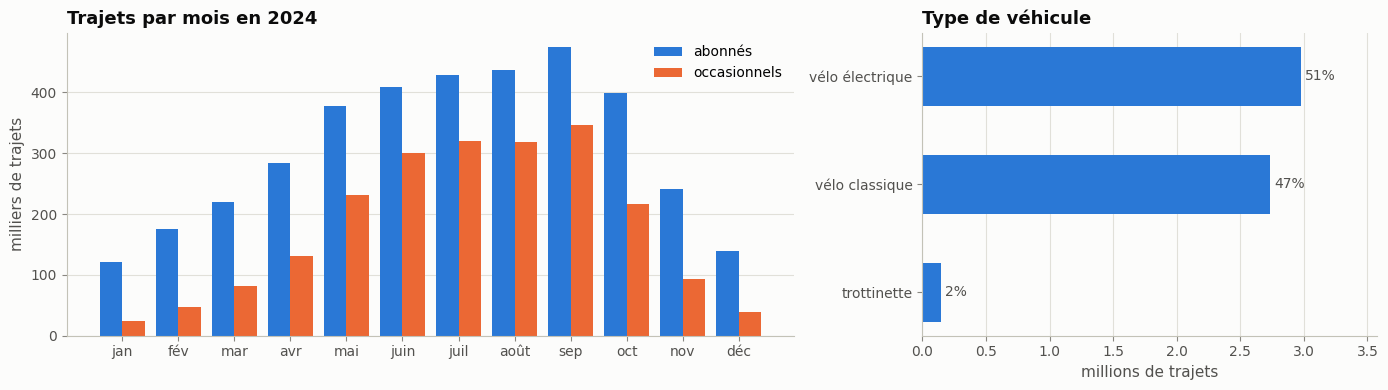

Été (juin-sept.) / hiver (déc.-fév.) : 5.6 fois plus de trajets


In [13]:
par_mois = trajets.groupBy("mois", "member_casual").count().toPandas().pivot(index="mois", columns="member_casual", values="count")
noms_mois = ["jan", "fév", "mar", "avr", "mai", "juin", "juil", "août", "sep", "oct", "nov", "déc"]

fig, (g, d) = plt.subplots(1, 2, figsize=(14, 4), gridspec_kw={"width_ratios": [1.6, 1]})
x = np.arange(12)
g.bar(x - 0.2, par_mois["member"] / 1e3, width=0.4, color=BLEU, label="abonnés")
g.bar(x + 0.2, par_mois["casual"] / 1e3, width=0.4, color=ORANGE, label="occasionnels")
g.set_xticks(x, noms_mois); g.set_ylabel("milliers de trajets"); g.legend()
g.set_title("Trajets par mois en 2024"); g.grid(axis="x", visible=False)

types = trajets.groupBy("rideable_type").count().toPandas().set_index("rideable_type")["count"].sort_values()
etiq = {"classic_bike": "vélo classique", "electric_bike": "vélo électrique", "electric_scooter": "trottinette"}
d.barh([etiq.get(t, t) for t in types.index], types.values / 1e6, color=BLEU, height=0.55)
for i, v in enumerate(types.values):
    d.text(v / 1e6 + 0.03, i, f"{v / types.sum():.0%}", va="center", color=ENCRE_2)
d.set_title("Type de véhicule"); d.set_xlabel("millions de trajets"); d.grid(axis="y", visible=False)
d.set_xlim(0, types.max() / 1e6 * 1.2)
plt.tight_layout(); plt.show()
print(f"Été (juin-sept.) / hiver (déc.-fév.) : {par_mois.loc[6:9].sum().sum() / par_mois.loc[[12, 1, 2]].sum().sum():.1f} fois plus de trajets")

L'hiver de Chicago est rude : il y a **plus de 5 fois plus de trajets en été qu'en hiver**. Les usagers occasionnels
(touristes, promenades) sont presque absents en hiver et nombreux en été. Les vélos électriques font désormais
un peu plus de la moitié des trajets.

### 2.2 Le rythme de la journée

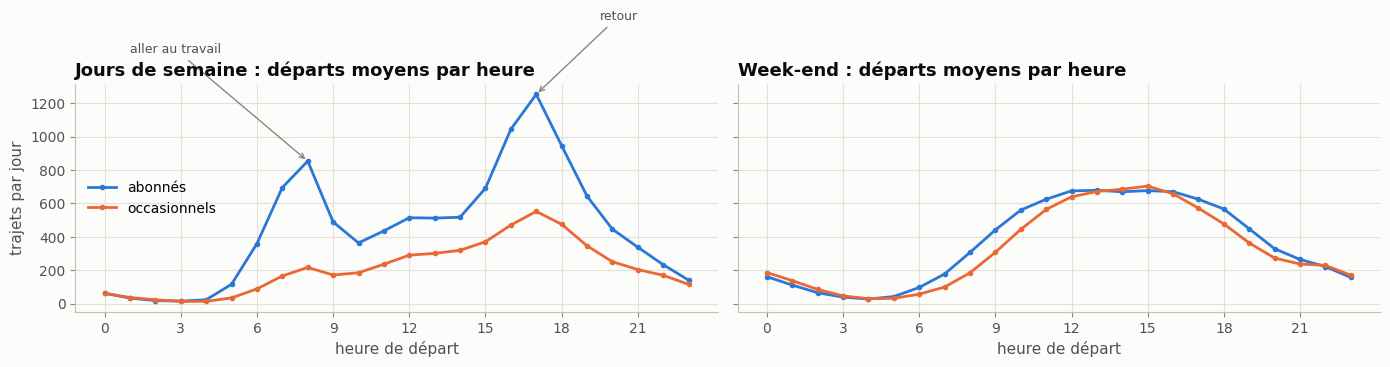

In [14]:
profil = (trajets.groupBy("weekend", "heure", "member_casual").count()
          .join(trajets.groupBy("weekend").agg(F.countDistinct("date").alias("jours")), "weekend")
          .withColumn("par_jour", F.col("count") / F.col("jours")).toPandas())
fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
for ax, w, titre in zip(axes, [0, 1], ["Jours de semaine", "Week-end"]):
    for u, c, lab in [("member", BLEU, "abonnés"), ("casual", ORANGE, "occasionnels")]:
        p = profil[(profil.weekend == w) & (profil.member_casual == u)].sort_values("heure")
        ax.plot(p["heure"], p["par_jour"], color=c, label=lab, marker="o", markersize=3)
    ax.set_title(f"{titre} : départs moyens par heure"); ax.set_xlabel("heure de départ"); ax.set_xticks(range(0, 24, 3))
axes[0].set_ylabel("trajets par jour"); axes[0].legend()
axes[0].annotate("aller au travail", (8, profil.query("weekend==0 & heure==8 & member_casual=='member'")["par_jour"].iloc[0]),
                 xytext=(1, 1500), fontsize=9, color=ENCRE_2, arrowprops=dict(arrowstyle="->", color=GRIS))
axes[0].annotate("retour", (17, profil.query("weekend==0 & heure==17 & member_casual=='member'")["par_jour"].iloc[0]),
                 xytext=(19.5, 1700), fontsize=9, color=ENCRE_2, arrowprops=dict(arrowstyle="->", color=GRIS))
plt.tight_layout(); plt.show()

En semaine, les abonnés dessinent **deux pics**, à 8 h et à 17 h : ils vont au travail à vélo. Le week-end, une
seule bosse l'après-midi : ce sont des balades. **L'heure et le jour de la semaine seront des variables
essentielles**, et leur effet dépend l'un de l'autre (un modèle linéaire aura du mal à le voir).

### 2.3 Durée des trajets

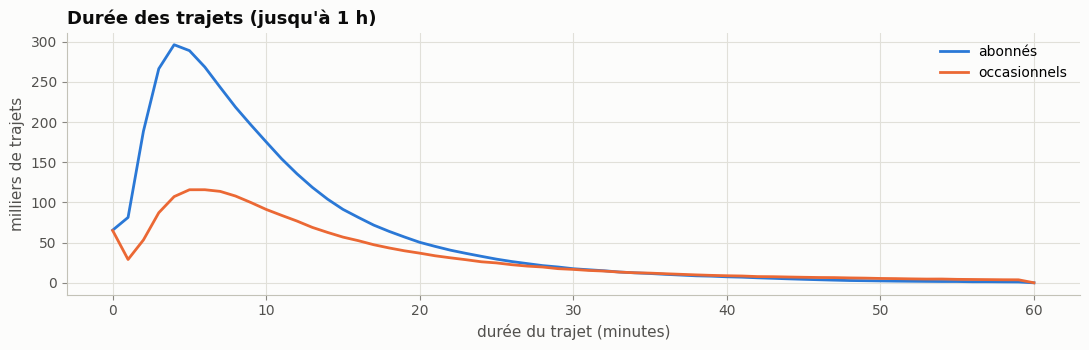

Durée : 1 % sous 0.3 min, médiane 9.7 min, 99 % sous 101 min
8,319 trajets de durée négative, nulle ou de plus de 24 h


In [15]:
durees = (trajets.where((F.col("duree_min") > 0) & (F.col("duree_min") <= 60))
          .groupBy(F.floor("duree_min").alias("minute"), "member_casual").count().toPandas())
fig, ax = plt.subplots(figsize=(11, 3.6))
for u, c, lab in [("member", BLEU, "abonnés"), ("casual", ORANGE, "occasionnels")]:
    p = durees[durees.member_casual == u].sort_values("minute")
    ax.plot(p["minute"], p["count"] / 1e3, color=c, label=lab)
ax.set_xlabel("durée du trajet (minutes)"); ax.set_ylabel("milliers de trajets"); ax.legend()
ax.set_title("Durée des trajets (jusqu'à 1 h)")
plt.tight_layout(); plt.show()
q = trajets.select(F.percentile_approx("duree_min", [0.01, 0.5, 0.99]).alias("q")).first()["q"]
aberrants = trajets.where((F.col("duree_min") <= 0) | (F.col("duree_min") > 24 * 60)).count()
print(f"Durée : 1 % sous {q[0]:.1f} min, médiane {q[1]:.1f} min, 99 % sous {q[2]:.0f} min")
print(f"{aberrants:,} trajets de durée négative, nulle ou de plus de 24 h")

Un trajet typique dure une dizaine de minutes ; les occasionnels roulent plus longtemps. Quelques milliers de
trajets ont une durée négative ou de plusieurs jours (vélo mal raccroché, panne) : on les retirera.

### 2.4 Où roule-t-on ?

1,808 stations de départ différentes
Les 300 plus utilisées font 86% des départs en station


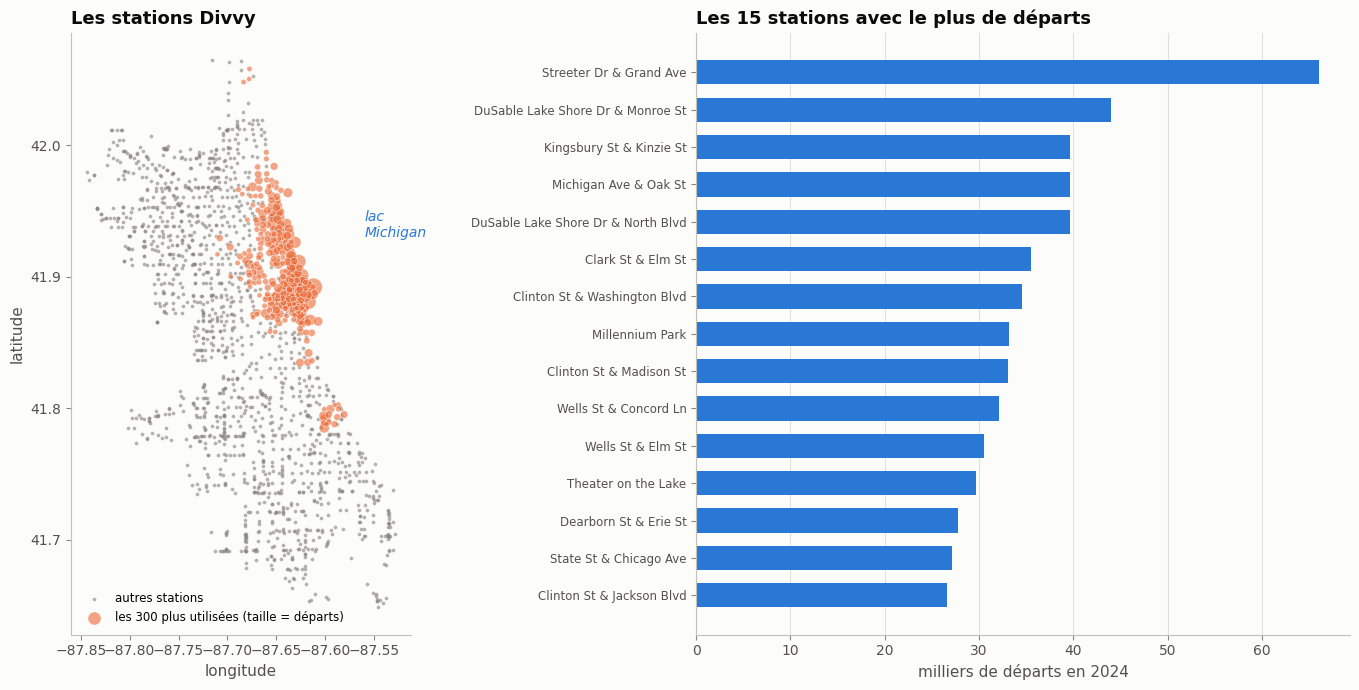

In [16]:
stations = (trajets.where(F.col("start_station_name").isNotNull())
            .groupBy("start_station_name")
            .agg(F.count("*").alias("departs"),
                 F.percentile_approx("start_lat", 0.5).alias("lat"), F.percentile_approx("start_lng", 0.5).alias("lng"))
            .toPandas().sort_values("departs", ascending=False).reset_index(drop=True))
print(f"{len(stations):,} stations de départ différentes")
NB_STATIONS = 300
# (Choisies sur toute l'année, jours de test compris : on veut simplement les plus grosses stations ; ce choix
#  ne donne au modèle aucun nombre de départs du test.)
top = stations.head(NB_STATIONS)
part_top = top["departs"].sum() / stations["departs"].sum()
print(f"Les {NB_STATIONS} plus utilisées font {part_top:.0%} des départs en station")

fig, (g, d) = plt.subplots(1, 2, figsize=(14, 7), gridspec_kw={"width_ratios": [1, 1.25]})
autres = stations.iloc[NB_STATIONS:]
autres = autres[autres["lat"].between(41.6, 42.1) & autres["lng"].between(-87.9, -87.5)]
g.scatter(autres["lng"], autres["lat"], s=3, color=GRIS, alpha=0.5, label="autres stations")
g.scatter(top["lng"], top["lat"], s=top["departs"] / 400, color=ORANGE, alpha=0.6, edgecolor="white", lw=0.5,
          label=f"les {NB_STATIONS} plus utilisées (taille = départs)")
g.set_aspect(1 / math.cos(math.radians(41.9))); g.legend(loc="lower left", fontsize=8.5)
g.text(-87.56, 41.93, "lac\nMichigan", color=BLEU, fontsize=10, style="italic")
g.set_title("Les stations Divvy"); g.set_xlabel("longitude"); g.set_ylabel("latitude"); g.grid(False)

t15 = top.head(15).iloc[::-1]
d.barh(t15["start_station_name"], t15["departs"] / 1e3, color=BLEU, height=0.65)
d.set_title("Les 15 stations avec le plus de départs"); d.set_xlabel("milliers de départs en 2024")
d.grid(axis="y", visible=False); d.tick_params(axis="y", labelsize=8.5)
plt.tight_layout(); plt.show()

Les stations les plus utilisées longent le lac Michigan (promenades, plages, musées) et le centre d'affaires
(*Loop*). La plupart des autres stations, en périphérie, voient passer quelques vélos par jour.

**Choix pour la suite :** on prédit les départs des **300 stations les plus utilisées**. Elles concentrent
l'essentiel des départs ; pour les petites stations, la réponse est presque toujours « 0 ou 1 vélo ».

### 2.5 La météo

On télécharge la météo de Chicago heure par heure pour 2024 (API gratuite [Open-Meteo](https://open-meteo.com),
données de réanalyse ERA5) : température, précipitations, vent.

In [17]:
FICHIER_METEO = Path("data/meteo_chicago_2024.json")
if not FICHIER_METEO.exists():
    url = ("https://archive-api.open-meteo.com/v1/archive?latitude=41.88&longitude=-87.63"
           "&start_date=2024-01-01&end_date=2024-12-31&hourly=temperature_2m,precipitation,wind_speed_10m"
           "&timezone=America%2FChicago")
    FICHIER_METEO.write_bytes(urllib.request.urlopen(url).read())
brut_meteo = json.loads(FICHIER_METEO.read_text())
h = brut_meteo["hourly"]
meteo = pd.DataFrame({"temperature": h["temperature_2m"], "pluie_mm": h["precipitation"], "vent_kmh": h["wind_speed_10m"]})
# Piège : Open-Meteo applique un décalage FIXE toute l'année (ici UTC−6, l'heure d'hiver), alors que les heures
# Divvy suivent l'heure d'été (UTC−5 du 10 mars au 3 novembre). On repasse en UTC puis en vraie heure de Chicago.
decalage = brut_meteo["utc_offset_seconds"]
print(f"Décalage horaire appliqué par Open-Meteo : {decalage / 3600:+.0f} h, toute l'année")
meteo["heure_locale"] = ((pd.to_datetime(pd.Series(h["time"])) - pd.Timedelta(seconds=decalage))
                         .dt.tz_localize("UTC").dt.tz_convert("America/Chicago").dt.tz_localize(None))
# La nuit du 3 novembre, 1 h du matin existe deux fois : on fait la moyenne des deux mesures.
meteo = meteo.groupby("heure_locale", as_index=False).mean()
attendues = pd.date_range("2024-01-01", "2025-01-01", freq="h", tz="America/Chicago", inclusive="left").tz_localize(None).unique()
print(f"{len(meteo):,} heures de météo, de {meteo.heure_locale.min()} à {meteo.heure_locale.max()}")
verifier("une mesure météo par heure réelle de Chicago en 2024 (8 783 h : 2 h du matin manque le 10 mars)",
         set(meteo["heure_locale"]) == set(attendues) and len(meteo) == len(attendues) == 8783
         and meteo.notna().all().all(), len(meteo))
meteo.describe().T.round(1)

Décalage horaire appliqué par Open-Meteo : -6 h, toute l'année


8,783 heures de météo, de 2024-01-01 00:00:00 à 2024-12-31 23:00:00
OK     une mesure météo par heure réelle de Chicago en 2024 (8 783 h : 2 h du matin manque le 10 mars)  (8783)


,count,mean,min,25%,50%,75%,max,std
heure_locale,8783,2024-07-01 23:48:40.414436864,2024-01-01 00:00:00,2024-04-01 12:30:00,2024-07-02 00:00:00,2024-10-01 11:30:00,2024-12-31 23:00:00,NaN
temperature,8783.0,11.815473,-24.9,3.4,12.8,20.3,36.2,10.525462
pluie_mm,8783.0,0.117352,0.0,0.0,0.0,0.0,19.8,0.630585
vent_kmh,8783.0,16.698759,0.0,11.2,15.7,21.4,45.1,7.467732


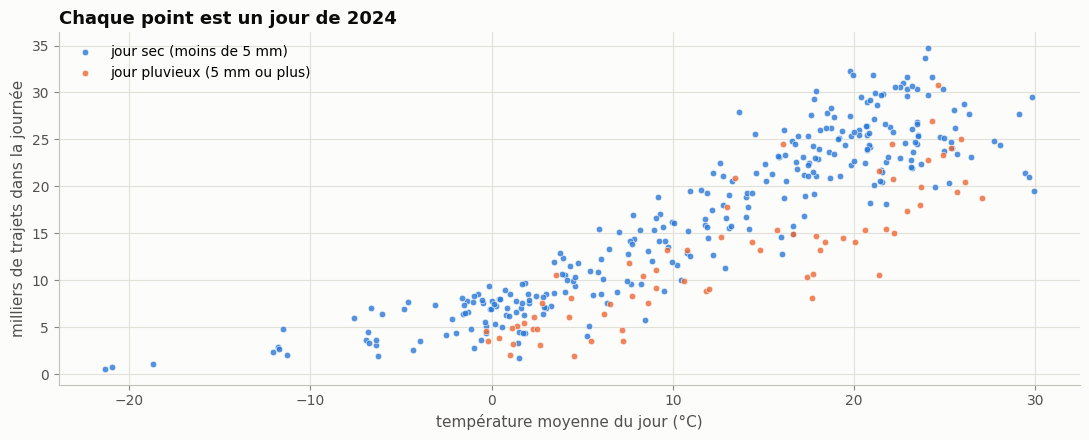

Corrélation trajets / température : 0.87


In [18]:
jour = trajets.groupBy("date").count().toPandas()
jour["date"] = pd.to_datetime(jour["date"])
mj = meteo.assign(date=meteo.heure_locale.dt.normalize()).groupby("date").agg(
    temperature=("temperature", "mean"), pluie=("pluie_mm", "sum"))
jour = jour.merge(mj, on="date")
jour["pluvieux"] = jour["pluie"] >= 5

fig, ax = plt.subplots(figsize=(11, 4.5))
for pl, c, lab in [(False, BLEU, "jour sec (moins de 5 mm)"), (True, ORANGE, "jour pluvieux (5 mm ou plus)")]:
    p = jour[jour.pluvieux == pl]
    ax.scatter(p["temperature"], p["count"] / 1e3, s=22, color=c, alpha=0.8, edgecolor="white", lw=0.5, label=lab)
ax.set_xlabel("température moyenne du jour (°C)"); ax.set_ylabel("milliers de trajets dans la journée")
ax.set_title("Chaque point est un jour de 2024"); ax.legend()
plt.tight_layout(); plt.show()
print(f"Corrélation trajets / température : {jour['count'].corr(jour['temperature']):.2f}")

Le lien est très fort : à −10 °C, quelques milliers de trajets par jour ; au-dessus de 20 °C, 20 000 à 30 000.
À température égale, **les jours de pluie sont en dessous** du nuage. La météo heure par heure sera donc une
variable du modèle.

**Ce que l'EDA nous apprend :** les départs dépendent de la station, de l'heure, du jour (semaine ou week-end),
de la saison et de la météo, avec des effets croisés (le pic de 8 h n'existe qu'en semaine).

## [Prétraitement]

## 3. Prétraitement : nettoyer

| Règle | Pourquoi |
|---|---|
| garder les trajets partis d'une **station** | on prédit les départs par station |
| durée entre **1 minute et 24 heures** | moins d'une minute : faux départ (l'usager raccroche aussitôt, Divvy les écarte aussi) ; plus de 24 h : vélo perdu ou mal raccroché |
| retirer les **doublons** de `ride_id` | un trajet compté deux fois |

Le résultat est sauvegardé dans HDFS au format **Parquet** : un format en colonnes, compressé, que Spark lit
beaucoup plus vite que du CSV (il ne lit que les colonnes demandées).

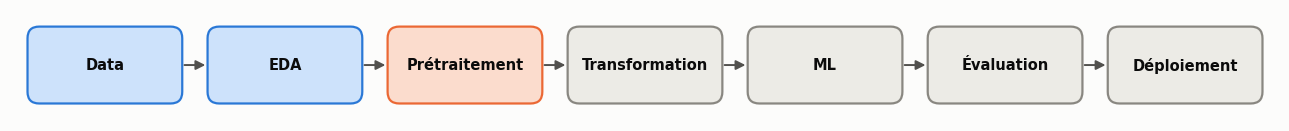

In [19]:
workflow(actif=3)

In [20]:
n0 = trajets.count()
etape1 = trajets.where(F.col("start_station_name").isNotNull()); n1 = etape1.count()
etape2 = etape1.where((F.col("duree_min") >= 1) & (F.col("duree_min") <= 24 * 60)); n2 = etape2.count()
propre = etape2.dropDuplicates(["ride_id"]); n3 = propre.count()
entonnoir = pd.DataFrame({"étape": ["tous les trajets", "partis d'une station", "durée de 1 min à 24 h", "sans doublon"],
                          "trajets": [n0, n1, n2, n3]})
entonnoir["retirés"] = -entonnoir["trajets"].diff().fillna(0).astype(int)
entonnoir

,étape,trajets,retirés
0,tous les trajets,5860568,0
1,partis d'une station,4786617,1073951
2,durée de 1 min à 24 h,4716503,70114
3,sans doublon,4716358,145


In [21]:
t0 = time.perf_counter()
(propre.select("ride_id", "rideable_type", "start_station_name", "end_station_name", "depart", "arrivee",
               "duree_min", "member_casual", "start_lat", "start_lng")
       .write.mode("overwrite").parquet(f"{HDFS}/divvy/propre"))
print(f"Écrit en Parquet dans HDFS en {time.perf_counter() - t0:.0f} s\n")
print("CSV bruts      :", hdfs("dfs", "-du", "-s", "-h", "/divvy/brut").split("  ")[0])
print("Parquet propre :", hdfs("dfs", "-du", "-s", "-h", "/divvy/propre").split("  ")[0])

t0 = time.perf_counter(); n_csv = spark.read.csv(f"{HDFS}/divvy/brut/", header=True, schema=schema_trajets, escape='"').select("start_station_name").distinct().count(); t_csv = time.perf_counter() - t0
t0 = time.perf_counter(); n_pq = spark.read.parquet(f"{HDFS}/divvy/propre").select("start_station_name").distinct().count(); t_pq = time.perf_counter() - t0
print(f"Stations distinctes : {t_csv:.1f} s depuis le CSV, {t_pq:.1f} s depuis le Parquet")

trajets.unpersist()
propre = spark.read.parquet(f"{HDFS}/divvy/propre")
verifier("le Parquet relu contient toutes les lignes nettoyées", propre.count() == n3, f"{n3:,}")
verifier("plus aucun doublon de ride_id", propre.select("ride_id").distinct().count() == n3)

Écrit en Parquet dans HDFS en 45 s



CSV bruts      : 1.1 G


Parquet propre : 211.2 M


Stations distinctes : 10.4 s depuis le CSV, 2.0 s depuis le Parquet


OK     le Parquet relu contient toutes les lignes nettoyées  (4,716,358)


OK     plus aucun doublon de ride_id


Le Parquet est **plusieurs fois plus petit** que les CSV et beaucoup plus rapide à relire : Spark ne lit que la
colonne utile au lieu de découper chaque ligne de texte.

## [Transformation]

## 4. Transformation : des trajets aux départs par station et par heure

Le modèle ne prédit pas des trajets un par un, mais un **nombre de départs** pour une station et une heure
données. Il faut donc **agréger**, puis ajouter les variables explicatives.

Point délicat : une heure **sans aucun départ** n'apparaît dans aucun trajet. Si on ne regardait que les heures
avec des trajets, le modèle n'apprendrait jamais à prédire 0. On construit donc la **grille complète**
300 stations × 8 783 heures de l'année (produit cartésien, `crossJoin`), puis on y reporte les départs ; les
cases vides valent 0.

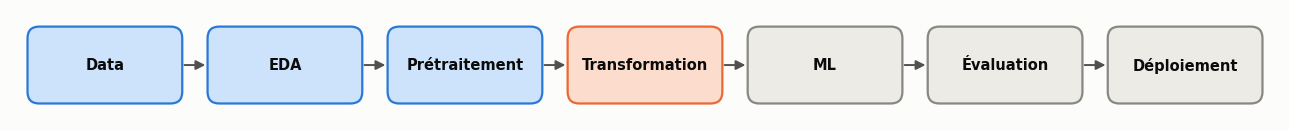

In [22]:
workflow(actif=4)

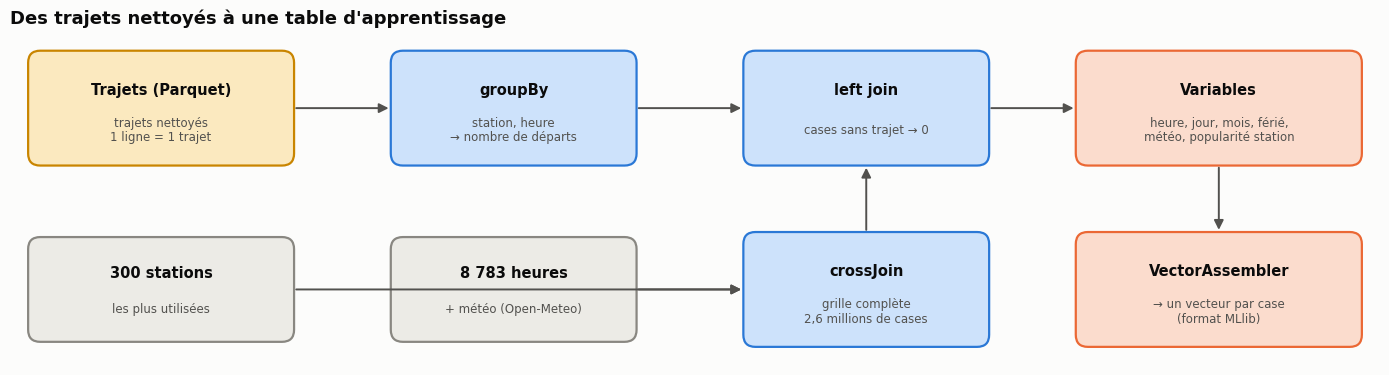

In [23]:
schema([
    dict(id="tr", x=0, y=2.3, texte="Trajets (Parquet)", sous="trajets nettoyés\n1 ligne = 1 trajet", couleur="jaune", l=2.6, h=1.1),
    dict(id="agg", x=3.5, y=2.3, texte="groupBy", sous="station, heure\n→ nombre de départs", couleur="bleu", l=2.4, h=1.1),
    dict(id="st", x=0, y=0.5, texte="300 stations", sous="les plus utilisées", couleur="gris", l=2.6, h=1.0),
    dict(id="hr", x=3.5, y=0.5, texte="8 783 heures", sous="+ météo (Open-Meteo)", couleur="gris", l=2.4, h=1.0),
    dict(id="grille", x=7.0, y=0.5, texte="crossJoin", sous="grille complète\n2,6 millions de cases", couleur="bleu", l=2.4, h=1.1),
    dict(id="join", x=7.0, y=2.3, texte="left join", sous="cases sans trajet → 0", couleur="bleu", l=2.4, h=1.1),
    dict(id="var", x=10.5, y=2.3, texte="Variables", sous="heure, jour, mois, férié,\nmétéo, popularité station", couleur="orange", l=2.8, h=1.1),
    dict(id="vec", x=10.5, y=0.5, texte="VectorAssembler", sous="→ un vecteur par case\n(format MLlib)", couleur="orange", l=2.8, h=1.1),
], [("tr", "agg"), ("st", "grille"), ("hr", "grille"), ("agg", "join"), ("grille", "join"), ("join", "var"), ("var", "vec")],
   taille=(14, 3.8), titre="Des trajets nettoyés à une table d'apprentissage")

In [24]:
noms_top = top["start_station_name"].tolist()
st_top = spark.createDataFrame(top[["start_station_name", "lat", "lng"]].rename(columns={"start_station_name": "station"}))

# Heures de l'année + météo, toutes deux en vraie heure locale de Chicago (météo convertie en 2.5).
heures = spark.createDataFrame(meteo.assign(heure_locale=meteo.heure_locale.dt.strftime("%Y-%m-%d %H:00:00")))
heures = heures.withColumn("heure_locale", F.to_timestamp("heure_locale"))

departs = (propre.where(F.col("start_station_name").isin(noms_top))
           .groupBy(F.col("start_station_name").alias("station"),
                    F.date_trunc("hour", "depart").alias("heure_locale"))
           .agg(F.count("*").alias("departs")))

FERIES_2024 = ["2024-01-01", "2024-01-15", "2024-02-19", "2024-05-27", "2024-06-19", "2024-07-04",
               "2024-09-02", "2024-10-14", "2024-11-11", "2024-11-28", "2024-12-25"]   # jours fériés fédéraux
grille = (st_top.crossJoin(heures)
          .join(departs, ["station", "heure_locale"], "left")
          .fillna(0, subset=["departs"])
          .withColumn("heure", F.hour("heure_locale"))
          .withColumn("jour_semaine", F.dayofweek("heure_locale"))
          .withColumn("mois", F.month("heure_locale"))
          .withColumn("jour_du_mois", F.dayofmonth("heure_locale"))
          .withColumn("weekend", F.col("jour_semaine").isin(1, 7).cast("int"))
          .withColumn("ferie", F.date_format("heure_locale", "yyyy-MM-dd").isin(FERIES_2024).cast("int"))
          .withColumn("pluie", (F.col("pluie_mm") > 0).cast("int")))
grille.cache()
t0 = time.perf_counter(); n_grille = grille.count()
print(f"Grille : {n_grille:,} cases (station x heure) en {time.perf_counter() - t0:.0f} s")
verifier("la grille a 300 x 8 783 cases", n_grille == NB_STATIONS * len(meteo), f"{n_grille:,}")
total_grille = grille.agg(F.sum("departs")).first()[0]
total_attendu = propre.where(F.col("start_station_name").isin(noms_top)).count()
print(f"Départs reportés dans la grille : {total_grille:,} sur {total_attendu:,}")
verifier("presque tous les départs des 300 stations sont dans la grille (entre 99,9 et 100 %)",
         0.999 < total_grille / total_attendu <= 1, f"{total_grille / total_attendu:.4%}")
hors_2024 = propre.where(F.col("start_station_name").isin(noms_top) & (F.year("depart") != 2024)).count()
print(f"dont départs datés hors de 2024 (absents de la grille) : {hors_2024:,}")

Grille : 2,634,900 cases (station x heure) en 345 s
OK     la grille a 300 x 8 783 cases  (2,634,900)


Départs reportés dans la grille : 4,041,803 sur 4,041,803
OK     presque tous les départs des 300 stations sont dans la grille (entre 99,9 et 100 %)  (100.0000%)


dont départs datés hors de 2024 (absents de la grille) : 0


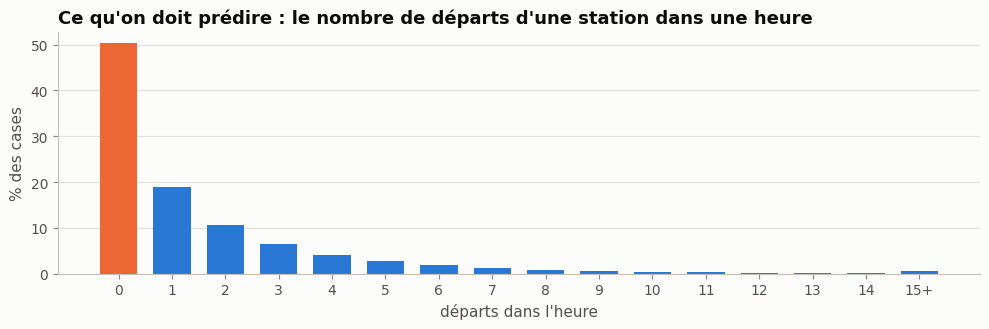

50% des cases valent 0, moyenne 1.53 départ par heure


In [25]:
distrib = grille.groupBy(F.least(F.col("departs"), F.lit(15)).alias("d")).count().toPandas().sort_values("d")
fig, ax = plt.subplots(figsize=(10, 3.4))
ax.bar(distrib["d"], distrib["count"] / n_grille * 100, color=[ORANGE if v == 0 else BLEU for v in distrib["d"]], width=0.7)
ax.set_xticks(range(16), [str(i) for i in range(15)] + ["15+"])
ax.set_xlabel("départs dans l'heure"); ax.set_ylabel("% des cases"); ax.grid(axis="x", visible=False)
ax.set_title("Ce qu'on doit prédire : le nombre de départs d'une station dans une heure")
plt.tight_layout(); plt.show()
print(f"{(distrib.loc[distrib.d == 0, 'count'].iloc[0] / n_grille):.0%} des cases valent 0, moyenne {total_grille / n_grille:.2f} départ par heure")

La plupart des cases valent 0 (la nuit, l'hiver), d'où l'intérêt de la grille complète.

### Découpage apprentissage / test

On ne tire **pas** les heures au hasard : deux heures voisines se ressemblent trop, et le modèle « tricherait »
en s'appuyant sur l'heure d'avant et l'heure d'après. Le test est la **dernière semaine de chaque mois** (du 24
à la fin du mois) : il couvre toutes les saisons, et le modèle ne l'a jamais vu.

### La popularité de la station

Le nom de la station seul ne dit rien à un modèle. On le remplace par la **moyenne des départs par heure de la
station, calculée sur l'apprentissage seulement** (c'est l'encodage par la cible du sujet 1, refait en Spark).

In [26]:
app = grille.where(F.col("jour_du_mois") < 24)
test = grille.where(F.col("jour_du_mois") >= 24)

popularite = app.groupBy("station").agg(F.avg("departs").alias("station_moy"))
profil_station = app.groupBy("station", "weekend", "heure").agg(F.avg("departs").alias("station_heure_moy"))
def enrichir(df):
    return df.join(F.broadcast(popularite), "station").join(F.broadcast(profil_station), ["station", "weekend", "heure"])
app, test = enrichir(app).cache(), enrichir(test).cache()
n_app, n_test = app.count(), test.count()
print(f"apprentissage : {n_app:,} cases   test : {n_test:,} cases ({n_test / (n_app + n_test):.0%})")
verifier("apprentissage + test = toute la grille", n_app + n_test == n_grille)
# Si les encodages avaient été calculés sur toute la grille (test compris), ils seraient différents :
moy_toute_grille = grille.groupBy("station").agg(F.avg("departs").alias("m")).toPandas().set_index("station")["m"]
moy_app = popularite.toPandas().set_index("station")["station_moy"]
verifier("station_moy vient de l'apprentissage seul (il diffère de la moyenne sur toute la grille)",
         (moy_app - moy_toute_grille.loc[moy_app.index]).abs().max() > 1e-6)

apprentissage : 1,986,900 cases   test : 648,000 cases (25%)
OK     apprentissage + test = toute la grille


OK     station_moy vient de l'apprentissage seul (il diffère de la moyenne sur toute la grille)


Deux variables résument la station, calculées sur l'apprentissage :

- `station_moy` : départs moyens par heure (la station est-elle grande ou petite ?) ;
- `station_heure_moy` : départs moyens de la station à cette heure, en semaine ou le week-end (son rythme
  propre : une station de bureaux a son pic à 17 h, une station de plage le dimanche après-midi).

Les autres variables :

| Variable | Contenu |
|---|---|
| `heure`, `jour_semaine`, `mois`, `weekend`, `ferie` | le calendrier |
| `temperature`, `pluie_mm`, `pluie`, `vent_kmh` | la météo de l'heure |
| `lat`, `lng` | la position de la station |

## [ML]

## 5. ML : trois modèles Spark MLlib

Chaque modèle est un **Pipeline MLlib**, l'équivalent du Pipeline de scikit-learn : les étapes de préparation
puis le modèle, appris et sauvegardés ensemble.

| Modèle | Idée |
|---|---|
| **Moyenne historique** (référence) | la case vaut `station_heure_moy` : la moyenne de la station à cette heure, en semaine ou le week-end. Pas de météo, pas de saison. |
| **Régression linéaire** | somme pondérée des variables ; l'heure et le jour sont encodés en one-hot (une colonne par heure) |
| **Forêt aléatoire** | 40 arbres appris en parallèle sur des échantillons différents |
| **Gradient boosting** (GBT) | des arbres appris l'un après l'autre, chacun corrigeant les erreurs des précédents |

Mesures : **RMSE** (racine de l'erreur quadratique moyenne, pénalise les grosses erreurs), **MAE** (erreur
moyenne, en vélos) et **R²**.

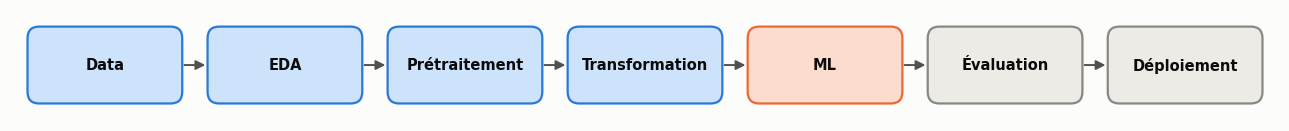

In [27]:
workflow(actif=5)

In [28]:
from pyspark.ml import Pipeline, PipelineModel
from pyspark.ml.feature import VectorAssembler, OneHotEncoder
from pyspark.ml.regression import LinearRegression, RandomForestRegressor, GBTRegressor
from pyspark.ml.evaluation import RegressionEvaluator

NUM = ["temperature", "pluie_mm", "pluie", "vent_kmh", "weekend", "ferie", "station_moy", "station_heure_moy", "lat", "lng"]
ARBRES = NUM + ["heure", "jour_semaine", "mois"]

def evaluer(pred, col="prediction"):
    return {m: RegressionEvaluator(labelCol="departs", predictionCol=col, metricName=m).evaluate(pred)
            for m in ["rmse", "mae", "r2"]}

resultats = {"Moyenne historique": {**evaluer(test, "station_heure_moy"), "entraînement (s)": 0.0}}

pipelines = {
    "Régression linéaire": Pipeline(stages=[
        OneHotEncoder(inputCols=["heure", "jour_semaine", "mois"], outputCols=["heure_oh", "jour_oh", "mois_oh"]),
        VectorAssembler(inputCols=NUM + ["heure_oh", "jour_oh", "mois_oh"], outputCol="features"),
        LinearRegression(labelCol="departs", regParam=0.01)]),
    "Forêt aléatoire": Pipeline(stages=[
        VectorAssembler(inputCols=ARBRES, outputCol="features"),
        RandomForestRegressor(labelCol="departs", numTrees=40, maxDepth=12, subsamplingRate=0.5, seed=0)]),
    "Gradient boosting": Pipeline(stages=[
        VectorAssembler(inputCols=ARBRES, outputCol="features"),
        GBTRegressor(labelCol="departs", maxIter=60, maxDepth=7, stepSize=0.15, subsamplingRate=0.7, seed=0)]),
}
modeles, predictions = {}, {}
for nom, pipe in pipelines.items():
    t0 = time.perf_counter()
    modeles[nom] = pipe.fit(app)
    duree = time.perf_counter() - t0
    predictions[nom] = modeles[nom].transform(test).cache()
    resultats[nom] = {**evaluer(predictions[nom]), "entraînement (s)": duree}
    print(f"{nom:20s} entraîné en {duree:5.0f} s   R² = {resultats[nom]['r2']:.3f}")

tableau = pd.DataFrame(resultats).T.rename(columns={"rmse": "RMSE", "mae": "MAE (vélos)", "r2": "R²"})
tableau.round(3)

Régression linéaire  entraîné en    17 s   R² = 0.467


Forêt aléatoire      entraîné en   570 s   R² = 0.593


Gradient boosting    entraîné en   408 s   R² = 0.604


,RMSE,MAE (vélos),R²,entraînement (s)
Moyenne historique,2.157,1.220,0.392,0.000
Régression linéaire,2.020,1.223,0.467,16.984
Forêt aléatoire,1.765,1.009,0.593,569.569
Gradient boosting,1.739,0.999,0.604,408.396


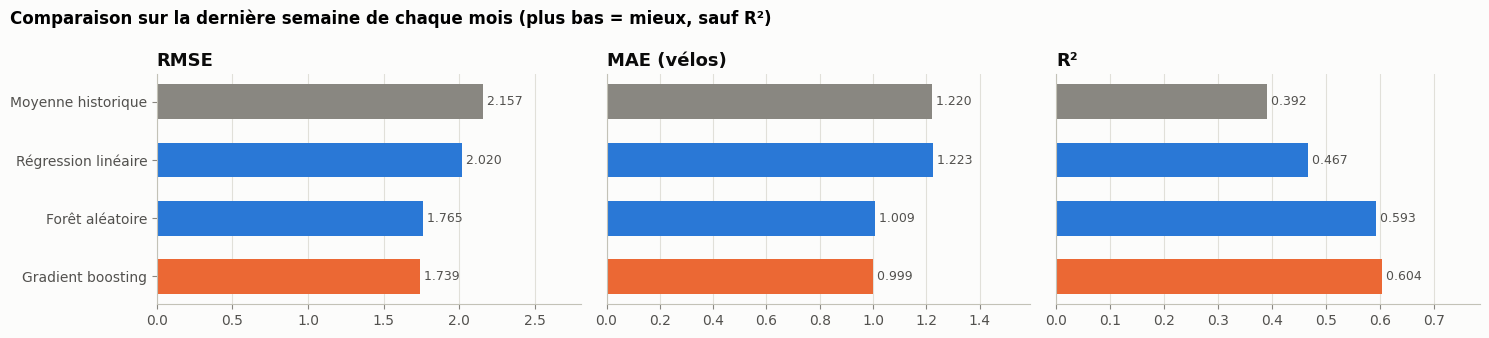

Meilleur modèle : Gradient boosting
OK     le meilleur modèle bat la moyenne historique (RMSE)
OK     le meilleur modèle explique plus de 60 % de la variance  (R² = 0.604)


In [29]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.4))
couleurs = [GRIS, BLEU, BLEU, ORANGE]
for ax, col, fmt in zip(axes, ["RMSE", "MAE (vélos)", "R²"], ["{:.3f}", "{:.3f}", "{:.3f}"]):
    ax.barh(tableau.index[::-1], tableau[col][::-1], color=couleurs[::-1], height=0.6)
    for i, v in enumerate(tableau[col][::-1]):
        ax.text(v, i, " " + fmt.format(v), va="center", fontsize=9, color=ENCRE_2)
    ax.set_title(col); ax.grid(axis="y", visible=False); ax.set_xlim(0, tableau[col].max() * 1.3)
axes[1].set_yticks([]); axes[2].set_yticks([])
fig.suptitle("Comparaison sur la dernière semaine de chaque mois (plus bas = mieux, sauf R²)",
             x=0.01, ha="left", fontweight="bold")
plt.tight_layout(); plt.show()

meilleur = tableau.drop("Moyenne historique")["RMSE"].idxmin()
print("Meilleur modèle :", meilleur)
verifier("le meilleur modèle bat la moyenne historique (RMSE)", tableau.loc[meilleur, "RMSE"] < tableau.loc["Moyenne historique", "RMSE"])
verifier("le meilleur modèle explique plus de 60 % de la variance", tableau.loc[meilleur, "R²"] > 0.6, f"R² = {tableau.loc[meilleur, 'R²']:.3f}")

## [Éval]

## 6. Évaluation

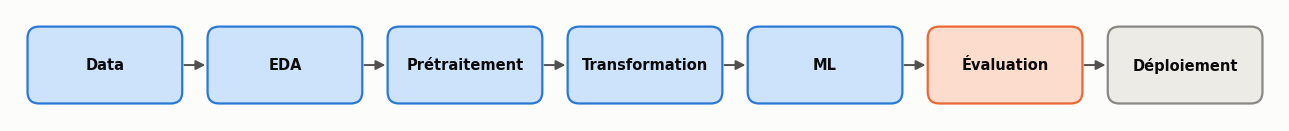

In [30]:
workflow(actif=6)

### 6.1 Une semaine à la station la plus fréquentée

Le plus parlant : comparer, heure par heure, les départs réels et prédits sur une semaine de test.

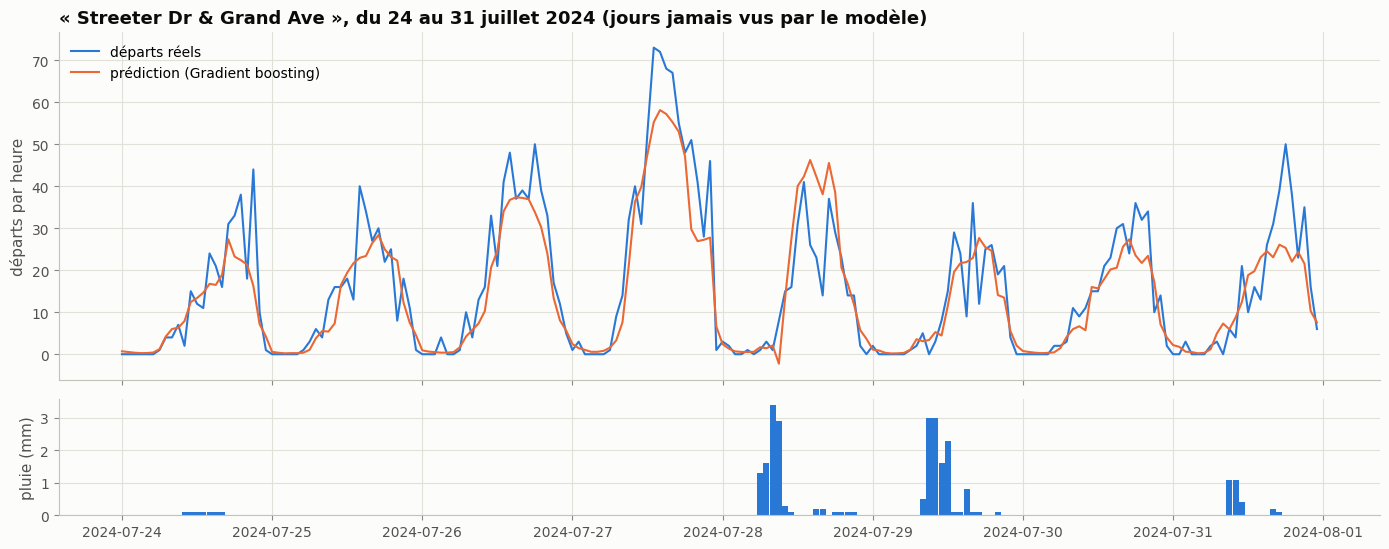

In [31]:
pred = predictions[meilleur]
station_star = noms_top[0]
semaine = (pred.where((F.col("station") == station_star) & (F.col("mois") == 7))
           .select("heure_locale", "departs", "prediction", "temperature", "pluie_mm")
           .orderBy("heure_locale").toPandas())
fig, (h, b) = plt.subplots(2, 1, figsize=(14, 5.6), sharex=True, gridspec_kw={"height_ratios": [3, 1]})
h.plot(semaine["heure_locale"], semaine["departs"], color=BLEU, lw=1.5, label="départs réels")
h.plot(semaine["heure_locale"], semaine["prediction"], color=ORANGE, lw=1.5, label=f"prédiction ({meilleur})")
h.set_ylabel("départs par heure"); h.legend(loc="upper left")
h.set_title(f"« {station_star} », du 24 au 31 juillet 2024 (jours jamais vus par le modèle)")
b.bar(semaine["heure_locale"], semaine["pluie_mm"], width=0.04, color=BLEU)
b.set_ylabel("pluie (mm)")
plt.tight_layout(); plt.show()

Le modèle suit le rythme jour/nuit et l'écart entre semaine et week-end. Il rate surtout les pointes
exceptionnelles (un événement, un beau dimanche) : aucune variable ne les annonce.

### 6.2 Où se trompe-t-il ?

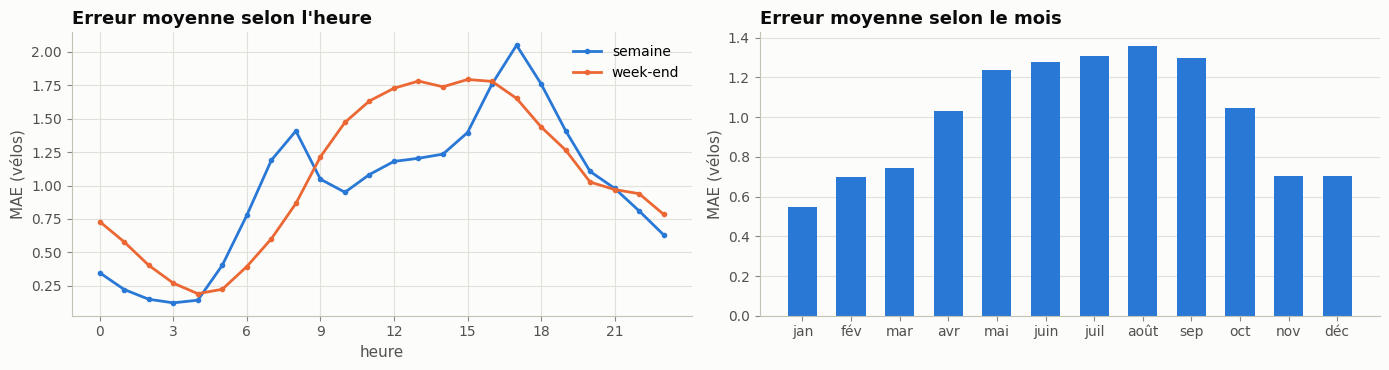

In [32]:
par_heure = (pred.withColumn("err", F.abs(F.col("prediction") - F.col("departs")))
             .groupBy("weekend", "heure").agg(F.avg("err").alias("mae"), F.avg("departs").alias("moy")).toPandas())
par_mois_err = (pred.withColumn("err", F.abs(F.col("prediction") - F.col("departs")))
                .groupBy("mois").agg(F.avg("err").alias("mae"), F.avg("departs").alias("moy")).toPandas().sort_values("mois"))
fig, (g, d) = plt.subplots(1, 2, figsize=(14, 3.8))
for w, c, lab in [(0, BLEU, "semaine"), (1, ORANGE, "week-end")]:
    p = par_heure[par_heure.weekend == w].sort_values("heure")
    g.plot(p["heure"], p["mae"], color=c, label=lab, marker="o", markersize=3)
g.set_title("Erreur moyenne selon l'heure"); g.set_xlabel("heure"); g.set_ylabel("MAE (vélos)"); g.legend()
g.set_xticks(range(0, 24, 3))
d.bar(par_mois_err["mois"], par_mois_err["mae"], color=BLEU, width=0.6)
d.set_xticks(range(1, 13), noms_mois); d.set_title("Erreur moyenne selon le mois"); d.set_ylabel("MAE (vélos)")
d.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

L'erreur suit l'activité : presque nulle la nuit et l'hiver (prédire 0 est facile), maximale aux heures de pointe
de l'été, quand il y a le plus de vélos. En proportion des départs, l'erreur est donc plus stable que ne le
suggère ce graphique.

### 6.3 Quelles variables comptent ?

Les modèles d'arbres de MLlib donnent l'**importance** de chaque variable : la part des améliorations apportées
par les découpages faits sur cette variable.

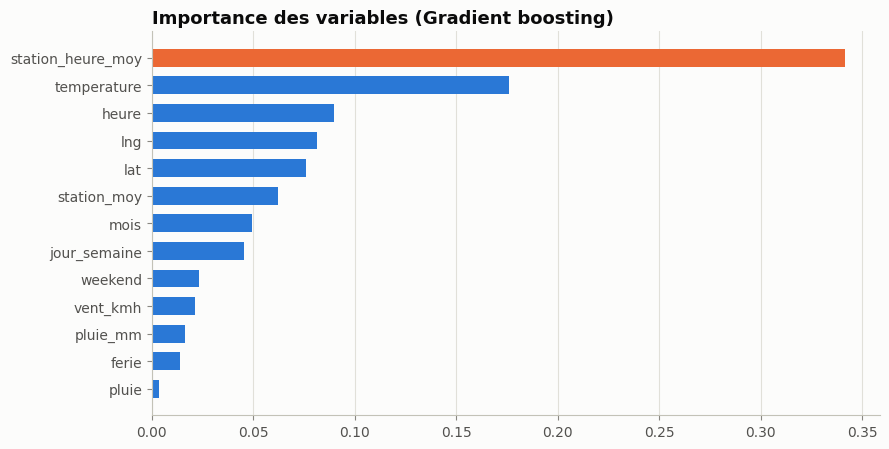

OK     le rythme de la station (station_heure_moy) fait partie des 3 variables les plus importantes


In [33]:
gbt = modeles[meilleur].stages[-1]
if hasattr(gbt, "featureImportances"):
    imp = pd.Series(gbt.featureImportances.toArray(), index=ARBRES).sort_values()
    fig, ax = plt.subplots(figsize=(9, 4.6))
    ax.barh(imp.index, imp.values, color=[ORANGE if v == imp.max() else BLEU for v in imp.values], height=0.65)
    ax.set_title(f"Importance des variables ({meilleur})"); ax.grid(axis="y", visible=False)
    plt.tight_layout(); plt.show()
    verifier("le rythme de la station (station_heure_moy) fait partie des 3 variables les plus importantes",
             "station_heure_moy" in imp.index[-3:])

Le **rythme propre de la station** domine : c'est lui qui dit si on est à une station de bureaux ou de plage, à
l'heure de pointe ou en pleine nuit. Viennent ensuite la **température** et le calendrier, qui modulent ce
rythme selon la saison et le temps qu'il fait.

### 6.4 Pandas contre Spark

Pour finir, la question du TP : **Spark est-il utile ici ?** On fait le même calcul (compter les départs de
chaque station sur l'année) avec pandas, qui doit tout charger en mémoire, et avec Spark.

In [34]:
import gc
t0 = time.perf_counter()
morceaux = [pd.read_csv(DOSSIER / f"{m}-divvy-tripdata.csv", usecols=["start_station_name"]) for m in MOIS]
df_pd = pd.concat(morceaux); del morceaux
res_pd = df_pd["start_station_name"].value_counts()
t_pd = time.perf_counter() - t0
mem_pd = df_pd.memory_usage(deep=True).sum() / 1e6
del df_pd; gc.collect()

t0 = time.perf_counter()
res_sp = spark.read.csv(f"{HDFS}/divvy/brut/", header=True, schema=schema_trajets, escape='"') \
              .groupBy("start_station_name").count().where(F.col("start_station_name").isNotNull()).toPandas()
t_sp_csv = time.perf_counter() - t0
t0 = time.perf_counter()
spark.read.parquet(f"{HDFS}/divvy/propre").groupBy("start_station_name").count().toPandas()
t_sp_pq = time.perf_counter() - t0

comparaison = pd.DataFrame({"temps (s)": [t_pd, t_sp_csv, t_sp_pq]},
    index=["pandas, 12 CSV locaux (1 colonne)", "Spark, 12 CSV dans HDFS", "Spark, Parquet dans HDFS"])
print(f"pandas : une seule colonne occupe déjà {mem_pd:,.0f} Mo en mémoire")
verifier("pandas et Spark trouvent les mêmes comptes par station",
         res_pd.sort_index().equals(res_sp.set_index("start_station_name")["count"].sort_index().rename("count")))
comparaison.round(1)

pandas : une seule colonne occupe déjà 468 Mo en mémoire
OK     pandas et Spark trouvent les mêmes comptes par station


,temps (s)
"pandas, 12 CSV locaux (1 colonne)",8.3
"Spark, 12 CSV dans HDFS",10.3
"Spark, Parquet dans HDFS",2.1


Sur **un seul ordinateur et 1 Go**, les deux outils restent dans le même ordre de grandeur : Spark lit les CSV
en parallèle sur les 12 cœurs, mais paie le coût de son organisation (planifier les tâches, passer par HDFS).
La vraie différence est ailleurs : pandas a dû **charger toute la colonne en mémoire** (le chiffre est affiché
au-dessus), alors que Spark ne garde que les comptes. Avec 100 Go, pandas ne pourrait plus charger les données,
tandis que Spark répartirait la lecture sur les blocs HDFS de dizaines de machines. Et le format compte autant
que l'outil : le Parquet rend Spark plusieurs fois plus rapide.

## [Déploiement]

## 7. Déploiement

1. Le Pipeline MLlib du meilleur modèle est **sauvegardé** avec `.save()` : un dossier (métadonnées JSON + arbres
   en Parquet) que l'on peut recharger avec `PipelineModel.load()`, ici ou sur un cluster.
2. Les variables propres aux stations (popularité, rythme, coordonnées) sont exportées en JSON.
3. L'appli **Streamlit** `app_velos.py` démarre une petite session Spark locale, recharge le modèle et affiche la
   prévision des départs, heure par heure, pour une station, une date et une météo choisies.

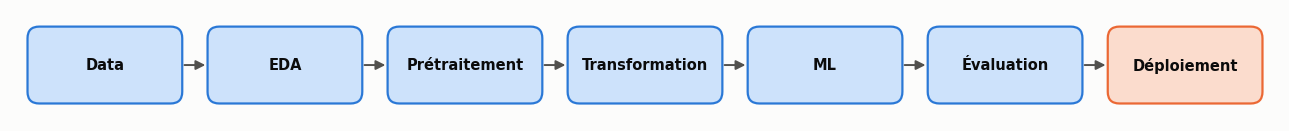

In [35]:
workflow(actif=7)

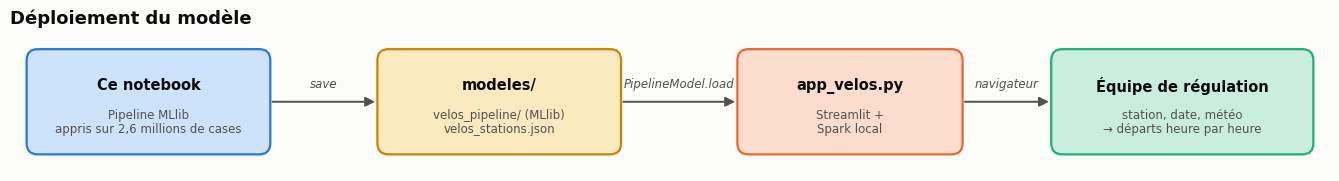

In [36]:
schema([
    dict(id="nb", x=0, y=0, texte="Ce notebook", sous="Pipeline MLlib\nappris sur 2,6 millions de cases", couleur="bleu", l=2.6, h=1.1),
    dict(id="mod", x=3.8, y=0, texte="modeles/", sous="velos_pipeline/ (MLlib)\nvelos_stations.json", couleur="jaune", l=2.6, h=1.1),
    dict(id="app", x=7.6, y=0, texte="app_velos.py", sous="Streamlit +\nSpark local", couleur="orange", l=2.4, h=1.1),
    dict(id="user", x=11.2, y=0, texte="Équipe de régulation", sous="station, date, météo\n→ départs heure par heure", couleur="vert", l=2.8, h=1.1),
], [("nb", "mod", "save"), ("mod", "app", "PipelineModel.load"), ("app", "user", "navigateur")],
   taille=(13.5, 2.2), titre="Déploiement du modèle")

In [37]:
# Modèle final : appris sur toute l'année (apprentissage + test), avec les variables de station recalculées.
popularite = grille.groupBy("station").agg(F.avg("departs").alias("station_moy"))
profil_station = grille.groupBy("station", "weekend", "heure").agg(F.avg("departs").alias("station_heure_moy"))
tout = enrichir(grille)
t0 = time.perf_counter()
final = pipelines[meilleur].fit(tout)
print(f"Modèle final appris sur {n_grille:,} cases en {time.perf_counter() - t0:.0f} s")

# Sauvegarde : MLlib écrit dans HDFS, puis on rapatrie le dossier dans modeles/ (copie par le volume Docker /data).
final.write().overwrite().save(f"{HDFS}/modeles/velos_pipeline")
subprocess.run(["docker", "exec", NAMENODE, "bash", "-c",
                "rm -rf /data/velos_pipeline && hdfs dfs -get /modeles/velos_pipeline /data/velos_pipeline"], check=True)
Path("modeles").mkdir(exist_ok=True)
shutil.rmtree("modeles/velos_pipeline", ignore_errors=True)
shutil.copytree("data/velos_pipeline", "modeles/velos_pipeline")

pop = popularite.toPandas().set_index("station")["station_moy"]
prof = profil_station.toPandas()
infos = {}
for _, r in top.iterrows():
    s = r["start_station_name"]
    p = prof[prof.station == s]
    infos[s] = {"lat": float(r["lat"]), "lng": float(r["lng"]), "station_moy": float(pop[s]),
                "profil": {f"{int(w)}-{int(hh)}": float(v) for w, hh, v in zip(p.weekend, p.heure, p.station_heure_moy)}}
Path("modeles/velos_stations.json").write_text(json.dumps(infos, ensure_ascii=False), encoding="utf-8")
taille = sum(f.stat().st_size for f in Path("modeles/velos_pipeline").rglob("*") if f.is_file()) / 1e6
print(f"modeles/velos_pipeline : {taille:.1f} Mo   modeles/velos_stations.json : {Path('modeles/velos_stations.json').stat().st_size / 1e3:.0f} ko")

Modèle final appris sur 2,634,900 cases en 442 s


modeles/velos_pipeline : 0.8 Mo   modeles/velos_stations.json : 425 ko


On recharge le modèle **depuis le dossier local** (comme le fera l'appli) et on vérifie qu'il prédit exactement
comme l'original. Puis on prépare une prévision comme dans l'appli : une station, un jour, une météo.

OK     le modèle rechargé depuis modeles/ prédit exactement comme l'original


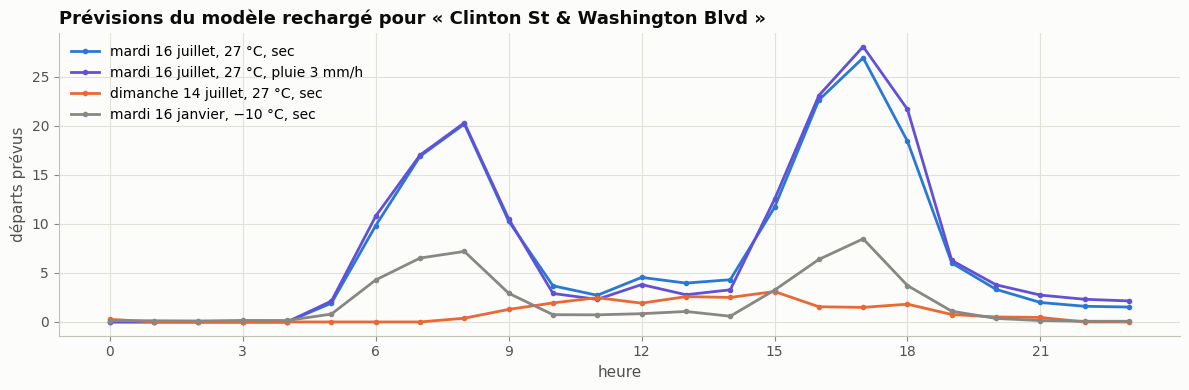

{'mardi 16 juillet, 27 °C, sec': 172.5, 'mardi 16 juillet, 27 °C, pluie 3 mm/h': 178.5, 'dimanche 14 juillet, 27 °C, sec': 23.0, 'mardi 16 janvier, −10 °C, sec': 49.9}
OK     −10 °C en janvier donne moins de départs que 27 °C en juillet  ([172.5, 49.9])


In [38]:
recharge = PipelineModel.load(str(Path("modeles/velos_pipeline").resolve().as_uri()))
echantillon = test.limit(2000)
a = final.transform(echantillon).select("prediction").toPandas()["prediction"]
b = recharge.transform(echantillon).select("prediction").toPandas()["prediction"]
verifier("le modèle rechargé depuis modeles/ prédit exactement comme l'original", np.allclose(a, b))

def prevoir(station, date, temperature, pluie_mm, vent_kmh=15.0):
    # Départs prévus heure par heure : même calcul que dans app_velos.py.
    d = pd.Timestamp(date); info = infos[station]
    weekend = int(d.dayofweek >= 5)
    lignes = [{"heure": h, "jour_semaine": (d.dayofweek + 1) % 7 + 1, "mois": d.month, "weekend": weekend,
               "ferie": int(d.strftime("%Y-%m-%d") in FERIES_2024), "temperature": float(temperature),
               "pluie_mm": float(pluie_mm), "pluie": int(pluie_mm > 0), "vent_kmh": float(vent_kmh),
               "station_moy": info["station_moy"], "station_heure_moy": info["profil"][f"{weekend}-{h}"],
               "lat": info["lat"], "lng": info["lng"]} for h in range(24)]
    p = recharge.transform(spark.createDataFrame(pd.DataFrame(lignes))).select("heure", "prediction").toPandas()
    p["prediction"] = p["prediction"].clip(lower=0)   # un nombre de départs n'est jamais négatif
    return p

cas = {"mardi 16 juillet, 27 °C, sec": ("2024-07-16", 27, 0), "mardi 16 juillet, 27 °C, pluie 3 mm/h": ("2024-07-16", 27, 3),
       "dimanche 14 juillet, 27 °C, sec": ("2024-07-14", 27, 0), "mardi 16 janvier, −10 °C, sec": ("2024-01-16", -10, 0)}
st_ex = "Clinton St & Washington Blvd" if "Clinton St & Washington Blvd" in infos else noms_top[0]
prev = {k: prevoir(st_ex, *v).set_index("heure")["prediction"] for k, v in cas.items()}
fig, ax = plt.subplots(figsize=(12, 4))
for (k, p), c in zip(prev.items(), [BLEU, VIOLET, ORANGE, GRIS]):
    ax.plot(p.index, p.values, color=c, label=k, marker="o", markersize=3)
ax.set_title(f"Prévisions du modèle rechargé pour « {st_ex} »"); ax.set_xlabel("heure"); ax.set_ylabel("départs prévus")
ax.set_xticks(range(0, 24, 3)); ax.legend()
plt.tight_layout(); plt.show()
totaux = {k: round(p.sum(), 1) for k, p in prev.items()}
print(totaux)
v = list(totaux.values())
verifier("−10 °C en janvier donne moins de départs que 27 °C en juillet", v[3] < v[0], [v[0], v[3]])

L'effet de la pluie se juge mieux sur **toutes les stations** et plusieurs saisons qu'à une seule station : on
prévoit la journée complète des 300 stations, au sec puis sous une pluie de 0,5 à 6 mm/h.

In [39]:
def lignes_reseau(date, temperature, pluie_mm):
    d = pd.Timestamp(date); we = int(d.dayofweek >= 5)
    return [{"st": s, "heure": h, "jour_semaine": (d.dayofweek + 1) % 7 + 1, "mois": d.month, "weekend": we,
             "ferie": int(d.strftime("%Y-%m-%d") in FERIES_2024), "temperature": float(temperature),
             "pluie_mm": float(pluie_mm), "pluie": int(pluie_mm > 0), "vent_kmh": 15.0,
             "station_moy": i["station_moy"], "station_heure_moy": i["profil"][f"{we}-{h}"], "lat": i["lat"], "lng": i["lng"]}
            for s, i in infos.items() for h in range(24)]
saisons = {"mardi 16 avril, 12 °C": ("2024-04-16", 12), "mardi 16 juillet, 27 °C": ("2024-07-16", 27),
           "mardi 15 octobre, 15 °C": ("2024-10-15", 15)}
PLUIES = [0, 0.5, 1, 3, 6]
effet = pd.DataFrame({nom: [recharge.transform(spark.createDataFrame(pd.DataFrame(lignes_reseau(d, t, mm))))
                                    .select(F.sum(F.greatest(F.col("prediction"), F.lit(0.0)))).first()[0] for mm in PLUIES]
                      for nom, (d, t) in saisons.items()}, index=[f"{mm} mm/h" for mm in PLUIES]).round(0)
print("Départs prévus sur la journée, 300 stations :")
print(effet.to_string())
orages = (meteo["pluie_mm"] >= 3).sum()
print(f"Heures de 2024 avec au moins 3 mm de pluie : {orages} sur {len(meteo):,}")
verifier("une pluie de 1 mm/h fait baisser le total prévu en avril, juillet et octobre",
         bool((effet.loc["1 mm/h"] < effet.loc["0 mm/h"]).all()), effet.loc[["0 mm/h", "1 mm/h"]].to_dict("list"))

Départs prévus sur la journée, 300 stations :
          mardi 16 avril, 12 °C  mardi 16 juillet, 27 °C  mardi 15 octobre, 15 °C
0 mm/h                  10896.0                  16280.0                  15087.0
0.5 mm/h                 6130.0                  13531.0                   9951.0
1 mm/h                   6593.0                  14574.0                   8983.0
3 mm/h                   6779.0                  17491.0                  10403.0
6 mm/h                   6242.0                  16515.0                  10050.0
Heures de 2024 avec au moins 3 mm de pluie : 80 sur 8,783
OK     une pluie de 1 mm/h fait baisser le total prévu en avril, juillet et octobre  ({'mardi 16 avril, 12 °C': [10896.0, 6593.0], 'mardi 16 juillet, 27 °C': [16280.0, 14574.0], 'mardi 15 octobre, 15 °C': [15087.0, 8983.0]})


Le froid fait nettement baisser les départs, et le profil change entre un mardi (pics du matin et du soir à
cette station du centre d'affaires) et un dimanche. Une pluie faible ou moyenne fait baisser le total du réseau
en toute saison. **Limite du modèle** : pour une forte averse en été (3 mm/h et plus), il prévoit parfois *plus*
de départs qu'au sec. Ces heures sont rares (voir le compte ci-dessus) : un orage d'été dure peu et tombe
souvent en fin d'après-midi, à l'heure de pointe. Le modèle n'a donc pas assez d'exemples pour séparer l'effet
de la pluie de celui de l'heure. Il faudrait plus d'années de données, ou imposer au modèle que la pluie ne peut
que faire baisser les départs (contrainte de monotonie, possible avec XGBoost ou LightGBM, pas avec le GBT de
MLlib).

### L'appli Streamlit

```bash
pip install streamlit pyspark
streamlit run app_velos.py
```

L'appli n'a pas besoin de HDFS : le modèle est lu depuis `modeles/velos_pipeline`. Elle démarre une session
Spark locale (une fois, gardée en cache), puis affiche les départs prévus heure par heure.

## [Tests]

## 8. Bilan des tests

In [40]:
bilan_tests()

19 tests réussis sur 19


,test,résultat,détail
0,HDFS répond et a un DataNode en vie,OK,1
1,les 12 fichiers mensuels de 2024 sont là,OK,
2,12 fichiers dans HDFS,OK,12
3,nombre de blocs = somme des arrondis supérieur...,OK,16
4,près de 6 millions de trajets en 2024,OK,"5,860,568"
5,une mesure météo par heure réelle de Chicago e...,OK,8783
6,le Parquet relu contient toutes les lignes net...,OK,"4,716,358"
7,plus aucun doublon de ride_id,OK,
8,la grille a 300 x 8 783 cases,OK,"2,634,900"
9,presque tous les départs des 300 stations sont...,OK,100.0000%


In [41]:
spark.stop()

## [Conclusion]

## Conclusion

| Étape | Ce qu'on a fait | Outil Big Data |
|---|---|---|
| **Data** | 12 fichiers mensuels (1,1 Go, 5,9 millions de trajets) + météo horaire | **HDFS** : fichiers coupés en blocs de 128 Mio |
| **EDA** | saisons, heures de pointe, durées, carte des stations, météo | **Spark SQL** : agrégations réparties, seuls les résultats reviennent dans pandas |
| **Prétraitement** | trajets sans station, durées aberrantes, doublons | Spark ; sauvegarde en **Parquet** dans HDFS, plus compact et plus rapide |
| **Transformation** | grille complète 300 stations × 8 783 heures (2,6 millions de cases), météo, calendrier, popularité | `crossJoin`, `join`, `groupBy` de Spark |
| **ML** | moyenne historique, régression linéaire, forêt aléatoire, gradient boosting | **Spark MLlib** (Pipeline) |
| **Évaluation** | semaine de test, erreur par heure et par mois, importance des variables, pandas contre Spark | MLlib `RegressionEvaluator` |
| **Déploiement** | `PipelineModel` sauvegardé, appli Streamlit | modèle MLlib rechargeable sur n'importe quelle machine Spark |

**Ce qu'on retient.** La démarche est la même que pour Tokyo, mais chaque étape est écrite pour passer à
l'échelle : stockage en blocs, calcul réparti, évaluation paresseuse, format en colonnes. Sur un portable et
1 Go, pandas reste dans le même ordre de grandeur ; sur des années de trajets de plusieurs villes, seul Spark suivrait, avec
exactement le même code.